# Reimplementation of Kaur (2024): GRU-assisted FL-DRL intrusion detection on TON_IoT

**Paper:** A. Kaur, "Intrusion Detection Approach for Industrial Internet of Things Traffic using Deep
Recurrent Reinforcement Learning Assisted Federated Learning", *IEEE Trans. Artificial Intelligence*,
2024, DOI 10.1109/TAI.2024.3443787.

**What is reimplemented (TON_IoT only):** a GRU classifier trained by 15 federated clients and
aggregated weighted by data size (Eqs. 18, 25). A DQN selects which clients take part each round and
their transmit power (Eqs. 5-8, 12-13). The energy model is Eqs. 1-4. The FedAvg baseline uses all
15 clients every round. Both IID and non-IID data are run.

**Tags** used in code comments and configs:
- **[PAPER]**: stated in the paper (with a citation).
- **[GAP-FILL]**: the paper omits it; the value was approved by the thesis author (see `kaur2024/SPEC.md`).
- **[EXTRA]**: added for thesis rigour, not part of the paper.

**Departures from the paper:**
1. **Local optimiser: plain SGD with η = 0.2** (Eqs. 17/24) instead of Adam (Table I(B)). Adam at
   0.2 collapsed to a single class (SPEC §7).
2. **Each traffic record is a length-1 sequence**, so the GRU uses no temporal context (G3).
3. **Split:** the test set matches Table II exactly (89,518 rows). Training has 371,485 rows
   instead of 395,467, because the file does not contain enough rows (G1).
4. **Protocol:** IID/non-IID with 15 clients is the paper's Edge-IIoT protocol (Table VIII),
   applied here to TON_IoT.
5. **Unstated details** were filled in: DQN top-8 of 15 selection, ε-greedy exploration, network
   sizes, energy constants and the Dirichlet(0.5) non-IID split (G1-G20).

**Notebook layout:**
- Part 1: the full source code (`%%writefile` cells; identical to `kaur2024/src`).
- Part 2: how to run it (switched off by default; a full run takes hours on CPU).
- Part 3: the saved results, with outputs already rendered.

## Setup
Run from anywhere inside the repository; the cell moves to the repository root.

In [ ]:
import os, json, sys
from pathlib import Path
p = Path.cwd()
while not (p / "kaur2024").is_dir() and p != p.parent:
    p = p.parent
os.chdir(p)
sys.path.insert(0, str(p / "kaur2024" / "src"))
print("repository root:", p)

# Part 1: Source code
Each cell writes one file of the implementation (the same files as in the repository).

### `kaur2024/configs/base.yaml`: Configuration: every setting with its tag

In [ ]:
%%writefile kaur2024/configs/base.yaml
# Base configuration for the Kaur (2024) reimplementation on TON_IoT.
# Every value is tagged: [PAPER] (with citation), [GAP-FILL Gn] (see kaur2024/SPEC.md, approved
# by the user 2026-11-07), or [EXTRA]. Experiment configs override only the keys they change.

data:
  # [GAP-FILL G1] file and location (Kaggle input path; override with --csv)
  csv: /kaggle/input/datasets/fadiabuzwayed/ton-iot-train-test-network/TON_IoT_Train_Test_Network.csv
  csv_sha256: 65d5465df1809b984fd10e4703bc9c012d1aefd11803773856364216f0a3520d   # [GAP-FILL G1]
  partitions_dir: kaur2024/results/partitions        # [EXTRA] written by src/phase1_data.py (G9)
  target: type                                        # [GAP-FILL G2]
  drop_cols: [ts, src_ip, dst_ip, src_port, dst_port, label]   # [GAP-FILL G2]
  high_cardinality: 50                                # [GAP-FILL G2] >50 unique in TRAIN -> drop
  clip_test: true                                     # [GAP-FILL G2d] clip min-max-scaled test to [0,1]

partition: iid            # iid | noniid_dir0.5      # [GAP-FILL G8] (overridden per experiment)
n_clients: 15             # [GAP-FILL C1] Table VIII protocol (Edge-IIoT in the paper) applied to TON_IoT

model:                    # [PAPER] Table I(B) p.7 and Sec. IV-B p.6
  gru_layers: 2           # [PAPER] Table I(B)
  hidden: 128             # [PAPER] Table I(B)
  dropout: 0.3            # [PAPER] Table I(B); placement [GAP-FILL G4]
  n_classes: 10           # [PAPER] Table II
  seq_len: 1              # [GAP-FILL G3] each record is a length-1 sequence

local:
  # [PAPER] Eqs. 17/24 plain gradient descent. Table I(B) says Adam, but Adam with eta = 0.2
  # collapses to one class (SPEC section 7); user chose SGD on 2026-11-08 (option A).
  optimizer: sgd
  lr: 0.2                 # [PAPER] Fig. 4 (eta = 0.2); see SPEC C3
  adam_betas: [0.9, 0.999]  # [GAP-FILL G19] only used if optimizer: adam
  adam_eps: 1.0e-7        # [GAP-FILL G19] only used if optimizer: adam
  reset_optimizer_each_round: true  # [GAP-FILL G19] fresh local optimizer every round (no state for SGD)
  batch_size: 20          # [PAPER] Fig. 4 (Lambda = 20)
  epochs: 5               # [PAPER] Table I(B) "Local Epochs 5"
  loss: cross_entropy     # [GAP-FILL G4] softmax CE, lambda = 0 (no Eq. 21 regulariser)
  partial_last_batch: true  # [GAP-FILL G19] Keras default: last batch may be smaller

fl:
  rounds: 100             # [PAPER] Table I(B)
  aggregation: weighted_by_size   # [PAPER] Eqs. 18, 25
  eval_rounds: [1, 50, 100]       # [PAPER] Table VIII (1, 50) + [EXTRA] 100 (G15)
  save_model_rounds: [50, 100]    # [EXTRA]

selection:
  method: dqn             # dqn | random | all   (overridden per experiment)
  k: 8                    # [GAP-FILL G5] top-8 of 15
  power_levels_dbm: [10, 20, 30]  # [GAP-FILL G5]
  fedavg_power_dbm: 30    # [GAP-FILL G12] FedAvg: all clients at max power

dqn:
  hidden: [64, 64]        # [GAP-FILL G6]
  lr: 1.0e-3              # [GAP-FILL G6]
  gamma: 0.99             # [PAPER] Fig. 5 p.9 (SPEC C2)
  buffer: 10000           # [PAPER] Table I(B)
  batch: 32               # [GAP-FILL G6]
  target_sync_every: 10   # [GAP-FILL G6] in gradient updates
  eps_start: 1.0          # [GAP-FILL G5]
  eps_end: 0.05           # [GAP-FILL G5]
  eps_decay_rounds: 50    # [GAP-FILL G5] linear, round 1 -> round 50
  updates_per_round: 1    # [GAP-FILL G6]

channel:                  # [PAPER] Sec. V-A p.9 unless tagged
  n0_dbm_per_hz: -174     # [PAPER] N0 = -174 dBm; read as density [GAP-FILL G11]
  max_power_dbm: 30       # [PAPER]
  b_max_hz: 1.0e+8        # [PAPER] 100 MHz
  path_loss: 1.0e-3       # [PAPER] average path loss, Rayleigh fading
  quant_bits: 16          # [PAPER] 16-bit quantisation
  cpu_hz: 1.1e+9          # [PAPER] 1100 MHz
  cycles_per_bit: 20      # [PAPER] varsigma = 20 cycles/bit
  kappa_cpu: 1.0e-28      # [GAP-FILL G11] effective switched capacitance (absent in paper)
  k_l: 5                  # [GAP-FILL G10] K_L = local epochs
  state_snr_power_dbm: 30 # [GAP-FILL G18] SNR in the state is computed at max power ...
  # ... and bandwidth B_max / k, before the action is chosen [GAP-FILL G18]

out_root: kaur2024/results   # [EXTRA]

### `kaur2024/configs/e1_iid_dqn.yaml`: Experiment E1: IID, DQN (proposed model)

In [ ]:
%%writefile kaur2024/configs/e1_iid_dqn.yaml
# E1 [PAPER method; GAP-FILL C1 protocol]: IID, 15 clients, DQN top-8 selection
inherit: base.yaml
name: e1_iid_dqn
partition: iid                 # [GAP-FILL G8/G9]
selection: {method: dqn}       # [PAPER] Sec. III-B; details [GAP-FILL G5, G6]

### `kaur2024/configs/e2_noniid_dqn.yaml`: Experiment E2: non-IID, DQN (proposed model)

In [ ]:
%%writefile kaur2024/configs/e2_noniid_dqn.yaml
# E2 [PAPER method; GAP-FILL C1 protocol]: non-IID Dirichlet(0.5), 15 clients, DQN top-8
inherit: base.yaml
name: e2_noniid_dqn
partition: noniid_dir0.5       # [GAP-FILL G8]
selection: {method: dqn}

### `kaur2024/configs/fedavg_iid.yaml`: Baseline: FedAvg, IID

In [ ]:
%%writefile kaur2024/configs/fedavg_iid.yaml
# FedAvg baseline [PAPER, baseline [10] p.9]: all 15 clients every round, no DRL, IID
inherit: base.yaml
name: fedavg_iid
partition: iid
selection: {method: all}       # [PAPER] 'All the device participating'; power [GAP-FILL G12]

### `kaur2024/configs/fedavg_noniid.yaml`: Baseline: FedAvg, non-IID

In [ ]:
%%writefile kaur2024/configs/fedavg_noniid.yaml
# FedAvg baseline [PAPER, baseline [10] p.9]: all 15 clients every round, no DRL, non-IID
inherit: base.yaml
name: fedavg_noniid
partition: noniid_dir0.5
selection: {method: all}

### `kaur2024/src/phase1_data.py`: Phase 1: data inspection, fixed split and client partitions (seed 0)

In [ ]:
%%writefile kaur2024/src/phase1_data.py
"""Phase 1 data work for the Kaur (2024) reimplementation on TON_IoT. No training code.

Does, in order:
  1. Inspect the CSV: shape, dtypes, missing values (NaN and the '-' placeholder),
     class counts of `type` vs Table II [PAPER, p.8].
  2. X3 [EXTRA] cardinality report for every string column.
  3. G1/G9 [GAP-FILL] create the train/test split ONCE with partition seed 0,
     using the per-class counts of Table II [PAPER, p.8].
  4. G8/G9 [GAP-FILL] create the IID and the non-IID (Dirichlet alpha=0.5) client
     partitions of the TRAIN indices, N=15 clients, partition seed 0. Plot them.
  5. X3 [EXTRA] duplicate rows shared between train and test.

Indices saved are 0-based row positions in the CSV (header excluded). The CSV's
sha256 is stored so every later run can check it uses the same file.

The test set is never used for any decision here: the split is made from labels
only, partitions use train indices only, and X3 only *reports* overlap.

Usage:
  python kaur2024/src/phase1_data.py --csv <path/to/train_test_network.csv>
Outputs (all under kaur2024/results/, never the repo's top-level results/):
  partitions/  split_train_idx.npy, split_test_idx.npy, iid_clients.npz,
               noniid_dir0.5_clients.npz, client_class_counts_*.csv, manifest.json,
               class_distribution_*.png
  phase1_data_report.md
  extra/x3_leakage.md
"""
import argparse
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]           # kaur2024/
RESULTS = ROOT / "results"
PART_DIR = RESULTS / "partitions"
EXTRA_DIR = RESULTS / "extra"

TARGET = "type"                                       # [GAP-FILL G2] target column
# [GAP-FILL G2] dropped before modelling (identifiers / timestamp / binary label)
DROP_COLS = ["ts", "src_ip", "dst_ip", "src_port", "dst_port", "label"]
HIGH_CARD = 50                                        # [GAP-FILL G2] >50 unique -> drop

# [PAPER] Table II, p.8 (TON_IoT). Keys are the CSV's `type` values.
TABLE_II = {  # type value: (paper name, train, test)
    "normal": ("Normal", 245000, 55000),
    "scanning": ("Scanning", 20000, 3973),
    "dos": ("DoS", 20000, 4000),
    "ddos": ("DDoS", 20000, 4000),
    "ransomware": ("Ransomware", 16030, 3970),
    "backdoor": ("Backdoor", 20000, 4000),
    "injection": ("Injection Attack", 20000, 4000),
    "xss": ("XSS", 13844, 6116),
    "password": ("Password Violations", 20000, 4000),
    "mitm": ("MITM", 593, 459),
}
CLASS_ORDER = list(TABLE_II)

PARTITION_SEED = 0          # [GAP-FILL G9]
N_CLIENTS = 15              # [PAPER] Table VIII protocol (see SPEC.md: Table VIII is Edge-IIoT)
DIRICHLET_ALPHA = 0.5       # [GAP-FILL G8]
MIN_CLIENT_SIZE = 20        # [GAP-FILL G8b] >= one local batch (batch size 20, Fig. 4)
MAX_DIRICHLET_TRIES = 1000  # [GAP-FILL G8b]


def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()


def md_table(df):
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(str(v) for v in r.values) + " |")
    return "\n".join(out)


# ---------------------------------------------------------------- split (G1, G9)
def make_split(y, rng):
    """[GAP-FILL G1] Per class: draw exactly Table II's test count at random, then up to
    Table II's train count from the remaining rows. If a class has too few rows, the
    test count is kept and train gets the remainder (shortfall reported). Rows beyond
    Table II's totals are left unused (reported)."""
    tr, te, rows = [], [], []
    for c in CLASS_ORDER:
        name, n_tr, n_te = TABLE_II[c]
        idx = np.flatnonzero(y == c)
        idx = idx[rng.permutation(len(idx))]
        k_te = min(n_te, len(idx))
        k_tr = min(n_tr, len(idx) - k_te)
        te.append(idx[:k_te])
        tr.append(idx[k_te:k_te + k_tr])
        rows.append({"class": name, "in_file": len(idx), "paper_train": n_tr, "ours_train": k_tr,
                     "paper_test": n_te, "ours_test": k_te,
                     "unused": len(idx) - k_te - k_tr,
                     "short_train": n_tr - k_tr, "short_test": n_te - k_te})
    unknown = sorted(set(np.unique(y)) - set(CLASS_ORDER))
    return np.sort(np.concatenate(tr)), np.sort(np.concatenate(te)), pd.DataFrame(rows), unknown


# ------------------------------------------------------------ partitions (G8, G9)
def iid_partition(train_idx, rng):
    perm = train_idx[rng.permutation(len(train_idx))]
    return [np.sort(p) for p in np.array_split(perm, N_CLIENTS)]


def dirichlet_partition(train_idx, y, rng):
    """[GAP-FILL G8] label-skew Dirichlet split (per class, client shares ~ Dir(alpha)).
    [GAP-FILL G8b] redraw until every client has >= MIN_CLIENT_SIZE samples."""
    for attempt in range(1, MAX_DIRICHLET_TRIES + 1):
        parts = [[] for _ in range(N_CLIENTS)]
        for c in CLASS_ORDER:
            idx = train_idx[y[train_idx] == c]
            idx = idx[rng.permutation(len(idx))]
            p = rng.dirichlet(np.full(N_CLIENTS, DIRICHLET_ALPHA))
            cuts = (np.cumsum(p) * len(idx)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx, cuts)):
                parts[k].append(chunk)
        parts = [np.sort(np.concatenate(p)) for p in parts]
        if min(len(p) for p in parts) >= MIN_CLIENT_SIZE:
            return parts, attempt
    raise RuntimeError("Dirichlet partition: no draw met the minimum client size")


def client_counts(parts, y):
    m = pd.DataFrame([[int((y[p] == c).sum()) for c in CLASS_ORDER] for p in parts],
                     columns=[TABLE_II[c][0] for c in CLASS_ORDER])
    m.index = [f"client_{k:02d}" for k in range(len(parts))]
    m["total"] = m.sum(axis=1)
    return m


def plot_counts(m, title, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    data = m.drop(columns="total")
    frac = data.div(data.sum(axis=1), axis=0)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, d, lab in [(axes[0], data, "samples"), (axes[1], frac, "fraction of client data")]:
        bottom = np.zeros(len(d))
        cmap = plt.get_cmap("tab10")
        for j, col in enumerate(d.columns):
            ax.bar(range(len(d)), d[col].values, bottom=bottom, color=cmap(j), label=col)
            bottom += d[col].values
        ax.set_xticks(range(len(d)), [str(i + 1) for i in range(len(d))])
        ax.set_xlabel("client"); ax.set_ylabel(lab)
    axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


# ------------------------------------------------------------------- X3 leakage
def duplicate_report(df, tr, te, feat_cols):
    """Rows of the test set whose feature vector also occurs in the training set."""
    out = []
    for label, cols in [("all columns except `type`/`label`",
                         [c for c in df.columns if c not in (TARGET, "label")]),
                        ("model features (after G2 drops, before encoding)", feat_cols)]:
        key = pd.util.hash_pandas_object(df[cols].astype(str), index=False).values
        ktr, kte = key[tr], key[te]
        shared = np.isin(kte, ktr)
        # label conflict: same features, a different `type` in train
        tr_map = pd.DataFrame({"k": ktr, "y": df[TARGET].values[tr]}).groupby("k")["y"].agg(set)
        conflict = sum(1 for k, yv in zip(kte[shared], df[TARGET].values[te][shared])
                       if tr_map[k] != {yv})
        per_class = pd.Series(df[TARGET].values[te][shared]).value_counts()
        out.append((label, int(shared.sum()), len(te), conflict, per_class,
                    int(pd.Series(ktr).duplicated().sum()), int(pd.Series(kte).duplicated().sum())))
    return out


def main():
    global RESULTS, PART_DIR, EXTRA_DIR
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv", required=True)
    ap.add_argument("--out", default=str(RESULTS), help="results root (default kaur2024/results)")
    args = ap.parse_args()
    csv = Path(args.csv)
    RESULTS = Path(args.out); PART_DIR = RESULTS / "partitions"; EXTRA_DIR = RESULTS / "extra"
    PART_DIR.mkdir(parents=True, exist_ok=True)
    EXTRA_DIR.mkdir(parents=True, exist_ok=True)

    df = pd.read_csv(csv, low_memory=False)
    y = df[TARGET].astype(str).str.strip().str.lower().values
    rep = [f"# Phase 1 data report: `{csv.name}`", "",
           f"- sha256: `{sha256(csv)}`", f"- shape: {df.shape[0]:,} rows x {df.shape[1]} columns", ""]

    # 1. dtypes and missing values
    obj = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]  # string columns
    miss = pd.DataFrame({
        "column": df.columns, "dtype": [str(t) for t in df.dtypes],
        "n_nan": [int(df[c].isna().sum()) for c in df.columns],
        "n_dash": [int((df[c].astype(str).str.strip() == "-").sum()) if c in obj else 0
                   for c in df.columns]})
    rep += ["## Columns, dtypes, missing values",
            "`n_dash` counts the '-' placeholder TON_IoT uses for 'not applicable'.", "",
            md_table(miss), ""]

    # 2. X3 cardinality
    card = pd.DataFrame({"column": obj,
                         "n_unique": [int(df[c].nunique(dropna=False)) for c in obj],
                         "top_values": [", ".join(map(str, df[c].value_counts().index[:5]))
                                        for c in obj]})
    card["G2 action"] = ["drop (G2 list)" if c in DROP_COLS else "target" if c == TARGET
                         else f"drop (>{HIGH_CARD} unique)" if n > HIGH_CARD else "one-hot"
                         for c, n in zip(card.column, card.n_unique)]
    feat_cols = [c for c in df.columns if c not in DROP_COLS + [TARGET]
                 and not (c in obj and df[c].nunique(dropna=False) > HIGH_CARD)]
    # NOTE: cardinality here is counted on the whole file only to *report* it; the
    # rule is re-applied on training rows only in Phase 2 (src/data.py).

    # 3. split
    rng = np.random.default_rng(PARTITION_SEED)
    tr, te, split_tab, unknown = make_split(y, rng)
    np.save(PART_DIR / "split_train_idx.npy", tr)
    np.save(PART_DIR / "split_test_idx.npy", te)
    rep += ["## Class counts vs Table II [PAPER, p.8] and the split [GAP-FILL G1]", "",
            md_table(split_tab), "",
            f"Totals: train {len(tr):,} (paper 395,467), test {len(te):,} (paper 89,518).",
            f"`type` values not in Table II: {unknown or 'none'}", ""]

    # 4. partitions
    iid = iid_partition(tr, rng)
    non, tries = dirichlet_partition(tr, y, rng)
    np.savez_compressed(PART_DIR / "iid_clients.npz", **{f"client_{k:02d}": p for k, p in enumerate(iid)})
    np.savez_compressed(PART_DIR / f"noniid_dir{DIRICHLET_ALPHA}_clients.npz",
                        **{f"client_{k:02d}": p for k, p in enumerate(non)})
    for tag, parts in [("iid", iid), (f"noniid_dir{DIRICHLET_ALPHA}", non)]:
        m = client_counts(parts, y)
        m.to_csv(PART_DIR / f"client_class_counts_{tag}.csv")
        plot_counts(m, f"TON_IoT train set, {N_CLIENTS} clients, {tag}",
                    PART_DIR / f"class_distribution_{tag}.png")
        rep += [f"## Client partition: {tag}", "", md_table(m.reset_index()), ""]
    rep += [f"Dirichlet draws needed to reach min client size {MIN_CLIENT_SIZE}: {tries}", ""]

    manifest = {"csv_name": csv.name, "csv_sha256": sha256(csv), "n_rows": int(len(df)),
                "partition_seed": PARTITION_SEED, "n_clients": N_CLIENTS,
                "dirichlet_alpha": DIRICHLET_ALPHA, "min_client_size": MIN_CLIENT_SIZE,
                "dirichlet_tries": tries, "index_base": "0-based CSV row position, header excluded",
                "rng": "numpy.default_rng(0); split, then IID, then Dirichlet, in that order"}
    (PART_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

    # 5. X3 duplicates
    x3 = ["# X3 [EXTRA] Leakage checks", "", f"File `{csv.name}`, split from partition seed 0.", "",
          "## Cardinality of every string column (whole file, report only)", "",
          md_table(card), "", "## Duplicate rows shared between train and test", ""]
    for label, n_sh, n_te, conf, per_cls, d_tr, d_te in duplicate_report(df, tr, te, feat_cols):
        x3 += [f"### Key: {label}",
               f"- test rows whose key also occurs in train: {n_sh:,} / {n_te:,} ({100 * n_sh / n_te:.2f}%)",
               f"- of those, with a different `type` in train: {conf:,}",
               f"- duplicates within train: {d_tr:,}; within test: {d_te:,}",
               "- shared test rows by class: " + ", ".join(f"{k} {v:,}" for k, v in per_cls.items()), ""]
    (EXTRA_DIR / "x3_leakage.md").write_text("\n".join(x3) + "\n")
    (RESULTS / "phase1_data_report.md").write_text("\n".join(rep) + "\n")
    print("\n".join(rep))
    print("\n".join(x3))


if __name__ == "__main__":
    main()

### `kaur2024/src/data.py`: Preprocessing (fit on train only): drop columns, one-hot, min-max (Eq. 19)

In [ ]:
%%writefile kaur2024/src/data.py
"""Data loading and preprocessing for the Kaur (2024) reimplementation on TON_IoT.

[PAPER] Sec. IV-A (p.5-6): remove unwanted features, handle missing values, one-hot encode
categorical features, min-max normalisation (Eq. 19).
Every encoder/scaler decision is fitted on TRAINING rows only (hard rule). The test set is
only transformed.

The split and client partitions are NOT created here: they are read from the files written
once by src/phase1_data.py (partition seed 0, [GAP-FILL G9]) and checked against the CSV's sha256.
"""
from __future__ import annotations

import hashlib
import json
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

REPO = Path(__file__).resolve().parents[2]

# [PAPER] Table II order; keys are the CSV's `type` values.
CLASS_ORDER = ["normal", "scanning", "dos", "ddos", "ransomware", "backdoor",
               "injection", "xss", "password", "mitm"]
CLASS_NAMES = ["Normal", "Scanning", "DoS", "DDoS", "Ransomware", "Backdoor",
               "Injection", "XSS", "Password", "MITM"]


def repo_path(p) -> Path:
    p = Path(p)
    return p if p.is_absolute() else REPO / p


def sha256_file(path, chunk=1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()


def sha256_array(a: np.ndarray) -> str:
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()[:16]


@dataclass
class Prepared:
    X_train: np.ndarray            # float32 [n_train, d]
    y_train: np.ndarray            # int64   [n_train]
    X_test: np.ndarray
    y_test: np.ndarray
    clients: list                  # list of arrays, positions into X_train
    feature_names: list
    dropped_high_card: list
    unseen_test_mask: np.ndarray   # [GAP-FILL G17] test rows whose encoded features never occur in train
    fingerprints: dict = field(default_factory=dict)


class Preprocessor:
    """Fitted on training rows only. [PAPER] Sec. IV-A; details [GAP-FILL G2, G2b-d]."""

    def __init__(self, drop_cols, target, high_card, clip_test):
        self.drop_cols, self.target = list(drop_cols), target
        self.high_card, self.clip_test = high_card, clip_test

    def fit(self, df_tr: pd.DataFrame):
        cols = [c for c in df_tr.columns if c not in self.drop_cols + [self.target]]
        self.str_cols = [c for c in cols if not pd.api.types.is_numeric_dtype(df_tr[c])]
        self.num_cols = [c for c in cols if c not in self.str_cols]
        # [GAP-FILL G2] cardinality counted on TRAIN rows only
        self.dropped = sorted(c for c in self.str_cols if df_tr[c].nunique(dropna=False) > self.high_card)
        self.cat_cols = [c for c in self.str_cols if c not in self.dropped]
        # [GAP-FILL G2b] '-' is its own category; G2c: unseen test categories -> all-zero
        self.categories = {c: sorted(df_tr[c].astype(str).unique()) for c in self.cat_cols}
        num = df_tr[self.num_cols].to_numpy(np.float64)
        self.vmin, self.vmax = num.min(0), num.max(0)   # [PAPER] Eq. 19 on train
        self.feature_names = self.num_cols + [f"{c}={v}" for c in self.cat_cols for v in self.categories[c]]
        return self

    def transform(self, df: pd.DataFrame, is_test: bool) -> np.ndarray:
        num = df[self.num_cols].to_numpy(np.float64)
        rng = np.where(self.vmax > self.vmin, self.vmax - self.vmin, 1.0)
        num = (num - self.vmin) / rng                    # [PAPER] Eq. 19
        num[:, self.vmax <= self.vmin] = 0.0             # constant-in-train column -> 0
        if is_test and self.clip_test:
            num = np.clip(num, 0.0, 1.0)                 # [GAP-FILL G2d]
        blocks = [num.astype(np.float32)]
        for c in self.cat_cols:                          # [PAPER] one-hot encoding
            cats = pd.Categorical(df[c].astype(str), categories=self.categories[c])
            codes = cats.codes
            oh = np.zeros((len(df), len(self.categories[c])), np.float32)
            ok = codes >= 0
            oh[np.flatnonzero(ok), codes[ok]] = 1.0
            blocks.append(oh)
        return np.concatenate(blocks, axis=1)


def _row_keys(X: np.ndarray) -> np.ndarray:
    v = np.ascontiguousarray(X).view(np.dtype((np.void, X.dtype.itemsize * X.shape[1])))
    return v.ravel()


def load_prepared(cfg: dict, csv_override: str | None = None, verify_sha: bool = True) -> Prepared:
    dc = cfg["data"]
    csv = Path(csv_override or dc["csv"])
    pdir = repo_path(dc["partitions_dir"])
    manifest = json.loads((pdir / "manifest.json").read_text())
    if verify_sha:
        sha = sha256_file(csv)
        if sha != dc["csv_sha256"] or sha != manifest["csv_sha256"]:
            raise RuntimeError(f"CSV sha256 {sha} does not match config/manifest; wrong file?")
    df = pd.read_csv(csv, low_memory=False)
    y_all = df[dc["target"]].astype(str).str.strip().str.lower().map({c: i for i, c in enumerate(CLASS_ORDER)})
    if y_all.isna().any():
        raise RuntimeError("unknown class label in CSV")
    y_all = y_all.to_numpy(np.int64)

    tr = np.load(pdir / "split_train_idx.npy")
    te = np.load(pdir / "split_test_idx.npy")
    assert len(np.intersect1d(tr, te)) == 0
    part_file = {"iid": "iid_clients.npz", "noniid_dir0.5": "noniid_dir0.5_clients.npz"}[cfg["partition"]]
    z = np.load(pdir / part_file)
    parts = [z[f"client_{k:02d}"] for k in range(cfg["n_clients"])]
    # positions of each client's CSV rows inside the training arrays
    pos = np.full(len(df), -1, np.int64)
    pos[tr] = np.arange(len(tr))
    clients = [pos[p] for p in parts]
    assert all((c >= 0).all() for c in clients), "client index outside the training split"
    assert sum(len(c) for c in clients) == len(tr)

    pre = Preprocessor(dc["drop_cols"], dc["target"], dc["high_cardinality"], dc["clip_test"])
    pre.fit(df.iloc[tr])
    X_tr = pre.transform(df.iloc[tr], is_test=False)
    X_te = pre.transform(df.iloc[te], is_test=True)

    # [GAP-FILL G17] "unseen" test rows: encoded feature vector absent from train (no labels used)
    unseen = ~np.isin(_row_keys(X_te), _row_keys(X_tr))

    fp = {"csv_sha256": manifest["csv_sha256"], "train_idx": sha256_array(tr), "test_idx": sha256_array(te),
          "partition": sha256_array(np.concatenate(parts)), "d": int(X_tr.shape[1]),
          "n_unseen_test": int(unseen.sum())}
    return Prepared(X_tr, y_all[tr], X_te, y_all[te], clients, pre.feature_names, pre.dropped, unseen, fp)

### `kaur2024/src/gru_model.py`: GRU classifier (2 x 128, dropout 0.3, 1 FC) and parallel client training

In [ ]:
%%writefile kaur2024/src/gru_model.py
"""GRU classifier. [PAPER] Table I(B) p.7 and Sec. IV-B p.6: input layer, 2 GRU layers with
128 hidden units, dropout 0.3, one fully connected output layer, Adam.

Two implementations of the SAME network, sharing one parameter layout (the names of
torch.nn.GRU / nn.Linear):

* `GRUClassifier`: a plain nn.Module (nn.GRU + nn.Linear). Used as the reference, for saved
  checkpoints and for evaluation.
* `functional_forward`: the same GRU equations written out for a stack of C models at once,
  shape [C, ...]. This lets all selected clients train in parallel on one GPU, with exactly
  the maths of nn.GRU (checked numerically in tests/test_kaur_core.py). It is an
  implementation speed-up only; each client's training is mathematically independent and
  identical to training it alone.

Gate order and equations follow torch.nn.GRU:
  r = sigma(W_ir x + b_ir + W_hr h + b_hr)
  z = sigma(W_iz x + b_iz + W_hz h + b_hz)
  n = tanh(W_in x + b_in + r * (W_hn h + b_hn))
  h' = (1 - z) * n + z * h,   h_0 = 0
Dropout [GAP-FILL G4]: on the output of GRU layer 1 (as nn.GRU's `dropout` argument does) and
on the last hidden state before the FC layer.
"""
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


class GRUClassifier(nn.Module):
    def __init__(self, d, hidden=128, layers=2, dropout=0.3, n_classes=10):
        super().__init__()
        self.gru = nn.GRU(d, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):                       # x: [B, T, d]
        out, _ = self.gru(x)
        return self.fc(self.drop(out[:, -1]))   # logits


def param_names(layers=2):
    names = []
    for l in range(layers):
        names += [f"gru.weight_ih_l{l}", f"gru.weight_hh_l{l}", f"gru.bias_ih_l{l}", f"gru.bias_hh_l{l}"]
    return names + ["fc.weight", "fc.bias"]


def functional_forward(P: dict, x: torch.Tensor, layers: int, dropout: float, training: bool):
    """x: [C, B, T, d] -> logits [C, B, n_classes]."""
    C, B, T, _ = x.shape
    inp = x
    for l in range(layers):
        W_ih, W_hh = P[f"gru.weight_ih_l{l}"], P[f"gru.weight_hh_l{l}"]   # [C,3H,in], [C,3H,H]
        b_ih, b_hh = P[f"gru.bias_ih_l{l}"], P[f"gru.bias_hh_l{l}"]       # [C,3H]
        H = W_hh.shape[-1]
        gi_all = torch.einsum("cbti,cgi->cbtg", inp, W_ih) + b_ih[:, None, None, :]
        h = x.new_zeros(C, B, H)
        outs = []
        for t in range(T):
            gi = gi_all[:, :, t]
            gh = torch.einsum("cbh,cgh->cbg", h, W_hh) + b_hh[:, None, :]
            i_r, i_z, i_n = gi.chunk(3, -1)
            h_r, h_z, h_n = gh.chunk(3, -1)
            r = torch.sigmoid(i_r + h_r)
            z = torch.sigmoid(i_z + h_z)
            n = torch.tanh(i_n + r * h_n)
            h = (1 - z) * n + z * h
            outs.append(h)
        inp = torch.stack(outs, 2)                          # [C, B, T, H]
        if l < layers - 1 and dropout > 0:
            inp = F.dropout(inp, dropout, training)         # as nn.GRU(dropout=...)
    last = F.dropout(inp[:, :, -1], dropout, training)      # [GAP-FILL G4]
    return torch.einsum("cbh,coh->cbo", last, P["fc.weight"]) + P["fc.bias"][:, None, :]


class Layout:
    """Flat parameter layout: all parameters of one model concatenated in `param_names` order,
    so C models are one tensor [C, total]. Used for fast stacked training, aggregation and
    the C_dq norm."""

    def __init__(self, state: dict, names):
        self.names, self.shapes, self.offsets = list(names), [], []
        off = 0
        for n in self.names:
            self.shapes.append(tuple(state[n].shape))
            self.offsets.append(off)
            off += state[n].numel()
        self.total = off

    def flatten(self, state: dict) -> torch.Tensor:
        return torch.cat([state[n].detach().reshape(-1) for n in self.names])

    def views(self, flat: torch.Tensor) -> dict:
        """flat [C, total] -> dict of [C, *shape] views (keeps autograd)."""
        C = flat.shape[0]
        return {n: flat[:, o:o + int(torch.Size(sh).numel())].view(C, *sh)
                for n, sh, o in zip(self.names, self.shapes, self.offsets)}

    def state_dict(self, flat_row: torch.Tensor) -> dict:
        return {n: flat_row[o:o + int(torch.Size(sh).numel())].view(*sh).detach().clone()
                for n, sh, o in zip(self.names, self.shapes, self.offsets)}


class FlatAdam:
    """Adam on a flat stacked parameter tensor [C, total], one step counter per client.
    `step(a)` updates only the first `a` rows (the clients that had a batch this step; the
    trainer orders clients so the active ones are always a prefix). Same update as
    torch.optim.Adam without weight decay: p -= lr * m_hat / (sqrt(v_hat) + eps)."""

    def __init__(self, flat: torch.Tensor, lr, betas=(0.9, 0.999), eps=1e-8):
        self.flat, self.lr, self.b1, self.b2, self.eps = flat, lr, betas[0], betas[1], eps
        self.m = torch.zeros_like(flat)
        self.v = torch.zeros_like(flat)
        self.t = torch.zeros(flat.shape[0], 1, device=flat.device, dtype=flat.dtype)

    @torch.no_grad()
    def step(self, a: int):
        p, g = self.flat[:a], self.flat.grad[:a]
        m, v, t = self.m[:a], self.v[:a], self.t[:a]
        t += 1
        m.mul_(self.b1).add_(g, alpha=1 - self.b1)
        v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2)
        bc1 = 1 - self.b1 ** t
        bc2 = 1 - self.b2 ** t
        denom = (v / bc2).sqrt_().add_(self.eps)
        p.sub_(self.lr * (m / bc1) / denom)
        self.flat.grad = None


class FlatSGD:
    """Plain gradient descent on the flat stacked tensor: w <- w - eta * grad.
    [PAPER] Eqs. 17 and 24 (no momentum, no weight decay). Chosen over Adam by the user on
    2026-11-08 (SPEC section 7, option A) because Adam with eta = 0.2 collapses."""

    def __init__(self, flat: torch.Tensor, lr, *unused, **unused_kw):
        self.flat, self.lr = flat, lr
        self.t = torch.zeros(flat.shape[0], 1, device=flat.device, dtype=flat.dtype)

    @torch.no_grad()
    def step(self, a: int):
        self.flat[:a] -= self.lr * self.flat.grad[:a]
        self.t[:a] += 1
        self.flat.grad = None


def n_params(state: dict) -> int:
    return int(sum(v.numel() for v in state.values()))

### `kaur2024/src/channel.py`: Channel and energy model (Eqs. 1-4)

In [ ]:
%%writefile kaur2024/src/channel.py
"""Channel and energy model. [PAPER] Eqs. 1-4 (p.4) and Sec. V-A (p.9); missing pieces are
[GAP-FILL G10, G11, G18] (see SPEC.md). The user has said the energy constants are not a focus:
the defaults are used as proposed and are not studied further.

Units: joules, watts, hertz, bits.
"""
from __future__ import annotations

import numpy as np


def dbm_to_w(dbm):
    return 10.0 ** ((np.asarray(dbm, dtype=np.float64) - 30.0) / 10.0)


class Channel:
    def __init__(self, ch: dict, n_clients: int, rng: np.random.Generator):
        self.c, self.n, self.rng = ch, n_clients, rng
        self.gain = self.draw()

    def draw(self) -> np.ndarray:
        """[PAPER] Rayleigh fading, average path loss 1e-3: power gain = 1e-3 * Exp(1).
        [GAP-FILL G11] redrawn per device per round from the training seed."""
        self.gain = self.c["path_loss"] * self.rng.exponential(1.0, self.n)
        return self.gain

    def snr(self, power_w, bandwidth_hz, gain=None):
        """[PAPER] zeta = P g / N0, with N0 as a density times bandwidth [GAP-FILL G11]."""
        g = self.gain if gain is None else gain
        noise_w = dbm_to_w(self.c["n0_dbm_per_hz"]) * bandwidth_hz
        return np.asarray(power_w) * g / noise_w

    def state_snr_db(self, k: int) -> np.ndarray:
        """[GAP-FILL G18] SNR seen in the DQN state: max power, bandwidth B_max / k."""
        s = self.snr(dbm_to_w(self.c["state_snr_power_dbm"]), self.c["b_max_hz"] / k)
        return 10.0 * np.log10(s)

    def energy(self, n_samples, d, n_params, power_w, n_selected, gain):
        """Per-device energies for the selected devices (arrays aligned with n_samples).
        Eq. 1: E_data = kappa * D * varsigma * upsilon^2
        Eq. 2: E_comp = kappa * D * varsigma * K_L * m * upsilon^2
        Eq. 3: E_comm = rho * q / (B log2(1 + zeta)), rho = P [GAP-FILL G11], U = 1, t' = 1
        """
        c = self.c
        D_bits = np.asarray(n_samples, np.float64) * d * c["quant_bits"]       # [GAP-FILL G11]
        m_mbit = n_params * c["quant_bits"] / 1e6                               # [GAP-FILL G11]
        q_bits = n_params * c["quant_bits"]                                     # [GAP-FILL G11]
        base = c["kappa_cpu"] * D_bits * c["cycles_per_bit"] * c["cpu_hz"] ** 2
        e_data = base                                                           # [PAPER] Eq. 1
        e_comp = base * c["k_l"] * m_mbit                                       # [PAPER] Eq. 2
        B = c["b_max_hz"] / n_selected                                          # [GAP-FILL G11]
        rate = B * np.log2(1.0 + self.snr(power_w, B, gain))
        e_comm = np.asarray(power_w) * q_bits / rate                            # [PAPER] Eq. 3
        return e_data, e_comp, e_comm

### `kaur2024/src/dqn_selector.py`: DQN client selection (Eqs. 6-8, 12-13), random and FedAvg selectors

In [ ]:
%%writefile kaur2024/src/dqn_selector.py
"""Client selection. The DQN selects clients; it never classifies traffic.

[PAPER] Sec. III-B (p.4-5): MDP with state Eq. 6, action Eq. 7, reward Eq. 8; DQN with a primary
and a target network and experience replay (Eqs. 12-13); replay buffer 10,000 (Table I(B));
gamma = 0.99 (Fig. 5).
[GAP-FILL G5, G6] network shape, top-k joint action, epsilon schedule, update schedule.

Joint-action Q [GAP-FILL G5]: the network outputs Q[i, p] for every client i and power level p.
The action picks k clients (and one power each); Q(s, a) = mean of the k chosen Q[i, p_i].
Target = r + gamma * mean of the top-k values of max_p Q_target(s', i, p).
"""
from __future__ import annotations

import numpy as np
import torch
import torch.nn as nn


class QNet(nn.Module):
    def __init__(self, state_dim, n_clients, n_powers, hidden=(64, 64)):
        super().__init__()
        layers, d = [], state_dim
        for h in hidden:                                   # [GAP-FILL G6] 2 x 64 ReLU
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, n_clients * n_powers))
        self.net = nn.Sequential(*layers)
        self.n, self.p = n_clients, n_powers

    def forward(self, s):                                  # [B, state_dim] -> [B, N, P]
        return self.net(s).view(-1, self.n, self.p)


class Replay:
    def __init__(self, cap, rng):
        self.cap, self.rng, self.buf, self.i = cap, rng, [], 0

    def push(self, tr):
        if len(self.buf) < self.cap:
            self.buf.append(tr)
        else:
            self.buf[self.i] = tr
        self.i = (self.i + 1) % self.cap

    def sample(self, n):                                   # [PAPER] uniform mini-batch, xi ~ U(D)
        idx = self.rng.choice(len(self.buf), n, replace=False)
        return [self.buf[j] for j in idx]


class Selector:
    """method: 'dqn' (paper), 'random' ([EXTRA] X2), 'all' (FedAvg baseline)."""

    def __init__(self, cfg: dict, n_clients: int, rng: np.random.Generator, device="cpu"):
        sc, dq = cfg["selection"], cfg["dqn"]
        self.method, self.k = sc["method"], (n_clients if sc["method"] == "all" else sc["k"])
        self.powers_dbm = np.array(sc["power_levels_dbm"], float)
        self.fedavg_power = sc["fedavg_power_dbm"]
        self.n, self.rng, self.dq, self.device = n_clients, rng, dq, device
        self.state_dim = 5 * n_clients                     # [PAPER] Eq. 6, 5 features per device
        self.updates, self.losses = 0, []
        if self.method == "dqn":
            self.q = QNet(self.state_dim, n_clients, len(self.powers_dbm), dq["hidden"]).to(device)
            self.q_t = QNet(self.state_dim, n_clients, len(self.powers_dbm), dq["hidden"]).to(device)
            self.q_t.load_state_dict(self.q.state_dict())  # [PAPER] target network
            self.opt = torch.optim.Adam(self.q.parameters(), lr=dq["lr"])
            self.replay = Replay(dq["buffer"], rng)

    def epsilon(self, rnd: int) -> float:
        """[GAP-FILL G5] linear 1.0 (round 1) -> 0.05 (round 50), then constant."""
        d = self.dq
        frac = min(1.0, (rnd - 1) / max(1, d["eps_decay_rounds"] - 1))
        return d["eps_start"] + frac * (d["eps_end"] - d["eps_start"])

    def select(self, state: np.ndarray, rnd: int):
        """Returns (selected client ids sorted, power index per selected client, explored flag)."""
        if self.method == "all":                            # [PAPER] FedAvg; power [GAP-FILL G12]
            p = int(np.flatnonzero(self.powers_dbm == self.fedavg_power)[0]) \
                if self.fedavg_power in self.powers_dbm else None
            return np.arange(self.n), np.full(self.n, p if p is not None else -1), False
        explore = self.method == "random" or self.rng.random() < self.epsilon(rnd)
        if explore:
            sel = np.sort(self.rng.choice(self.n, self.k, replace=False))
            return sel, self.rng.integers(0, len(self.powers_dbm), self.k), True
        with torch.no_grad():
            q = self.q(torch.as_tensor(state, dtype=torch.float32, device=self.device)[None])[0]
        best_q, best_p = q.max(1)
        sel = np.sort(torch.topk(best_q, self.k).indices.cpu().numpy())
        return sel, best_p.cpu().numpy()[sel], False

    def power_w(self, pidx: np.ndarray) -> np.ndarray:
        dbm = np.where(pidx >= 0, self.powers_dbm[np.clip(pidx, 0, None)], self.fedavg_power)
        return 10.0 ** ((dbm - 30.0) / 10.0)

    def observe(self, s, sel, pidx, r, s_next, done):
        if self.method != "dqn":
            return
        self.replay.push((s.astype(np.float32), sel.copy(), pidx.copy(), float(r),
                          s_next.astype(np.float32), float(done)))
        for _ in range(self.dq["updates_per_round"]):
            self._update()

    def _update(self):
        d = self.dq
        if len(self.replay.buf) < d["batch"]:
            return
        batch = self.replay.sample(d["batch"])
        dev = self.device
        s = torch.as_tensor(np.stack([b[0] for b in batch]), device=dev)
        s2 = torch.as_tensor(np.stack([b[4] for b in batch]), device=dev)
        r = torch.as_tensor([b[3] for b in batch], device=dev)
        done = torch.as_tensor([b[5] for b in batch], device=dev)
        sel = torch.as_tensor(np.stack([b[1] for b in batch]), device=dev)       # [B, k]
        pid = torch.as_tensor(np.stack([b[2] for b in batch]), device=dev)       # [B, k]
        q = self.q(s)                                                            # [B, N, P]
        q_sa = q[torch.arange(len(batch), device=dev)[:, None], sel, pid].mean(1)
        with torch.no_grad():
            nxt = self.q_t(s2).max(2).values.topk(self.k, dim=1).values.mean(1)
            target = r + d["gamma"] * (1 - done) * nxt                           # [PAPER] Eq. 12
        loss = ((target - q_sa) ** 2).mean()                                     # [PAPER] Eq. 12 (MSE)
        self.opt.zero_grad()
        loss.backward()
        self.opt.step()                                                          # [PAPER] Eq. 13
        self.updates += 1
        self.losses.append(float(loss))
        if self.updates % d["target_sync_every"] == 0:                           # [GAP-FILL G6]
            self.q_t.load_state_dict(self.q.state_dict())

### `kaur2024/src/evaluate.py`: Model-independent evaluation (accuracy, P/R/F1, AUC)

In [ ]:
%%writefile kaur2024/src/evaluate.py
"""Model-independent evaluation. [EXTRA] X5.

Takes (y_true, y_pred, y_score) from ANY model and returns the full metric set, so the same code
scores this reimplementation and any other model later.

[PAPER] Eqs. 31-34 (accuracy, recall, precision, F1), Fig. 7 (ROC/AUC), Table V (per-class and
macro P/R/F1). Multiclass versions are [GAP-FILL G13]: accuracy = fraction correct; macro =
unweighted mean over classes; AUC = one-vs-rest on scores (macro, per class, micro).

CLI:
  python kaur2024/src/evaluate.py preds.npz [--mask unseen_test_mask.npy] [--out metrics.json] [--roc roc.png]
  where preds.npz holds y_true [n], y_pred [n], y_score [n, n_classes].
"""
from __future__ import annotations

import argparse
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)

DEFAULT_CLASSES = ["Normal", "Scanning", "DoS", "DDoS", "Ransomware", "Backdoor",
                   "Injection", "XSS", "Password", "MITM"]


def evaluate(y_true, y_pred, y_score=None, class_names=DEFAULT_CLASSES, mask=None) -> dict:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if mask is not None:
        mask = np.asarray(mask, bool)
        y_true, y_pred = y_true[mask], y_pred[mask]
        y_score = None if y_score is None else np.asarray(y_score)[mask]
    if len(y_true) == 0:
        return {"n": 0, "accuracy": None}
    K = len(class_names)
    labels = np.arange(K)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    out = {
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]),
                          "support": int(s[i])} for i, c in enumerate(class_names)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }
    present = s > 0
    for avg in ("macro", "weighted"):
        pa, ra, fa, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels[present],
                                                        average=avg, zero_division=0)
        out[avg] = {"precision": float(pa), "recall": float(ra), "f1": float(fa)}
    if y_score is not None:
        y_score = np.asarray(y_score, np.float64)
        onehot = np.eye(K)[y_true]
        per = {}
        for i, c in enumerate(class_names):
            if 0 < onehot[:, i].sum() < len(y_true):
                per[c] = float(roc_auc_score(onehot[:, i], y_score[:, i]))
        out["auc"] = {
            "macro_ovr": float(np.mean(list(per.values()))) if per else None,
            "micro": float(roc_auc_score(onehot[:, present].ravel(), y_score[:, present].ravel())),
            "per_class": per,
        }
    return out


def plot_roc(y_true, y_score, path, title="ROC (micro-average, one-vs-rest)", K=10):
    """[PAPER] Fig. 7 style single ROC curve; micro-average OvR [GAP-FILL G13]."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    onehot = np.eye(K)[np.asarray(y_true)]
    fpr, tpr, _ = roc_curve(onehot.ravel(), np.asarray(y_score).ravel())
    auc = roc_auc_score(onehot.ravel(), np.asarray(y_score).ravel())
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.plot(fpr, tpr, label=f"ROC curve (area = {auc:.4f})")
    ax.plot([0, 1], [0, 1], "--", lw=1)
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.set_title(title)
    ax.legend(loc="lower right")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("preds")
    ap.add_argument("--mask", help="boolean .npy, e.g. unseen_test_mask.npy [GAP-FILL G17]")
    ap.add_argument("--out")
    ap.add_argument("--roc")
    a = ap.parse_args()
    z = np.load(a.preds)
    mask = np.load(a.mask) if a.mask else None
    res = evaluate(z["y_true"], z["y_pred"], z["y_score"] if "y_score" in z else None, mask=mask)
    txt = json.dumps(res, indent=2)
    if a.out:
        Path(a.out).write_text(txt)
    print(txt)
    if a.roc and "y_score" in z:
        plot_roc(z["y_true"], z["y_score"], a.roc)


if __name__ == "__main__":
    main()

### `kaur2024/src/fl.py`: Federated training loop (Algorithm 1)

In [ ]:
%%writefile kaur2024/src/fl.py
"""Federated training loop: GRU clients + DQN client selection. [PAPER] Algorithm 1 (p.7).

Per round t ([PAPER] Algorithm 1; details tagged inline):
  1. build the state s_t (Eq. 6) and select clients and transmit powers (Eq. 7)
  2. broadcast the global model; each selected client trains locally for 5 epochs, batch 20
  3. aggregate weighted by local dataset size (Eqs. 18, 25)
  4. update data quality C_dq (Eq. 5), energy (Eqs. 1-4), reward (Eq. 8), DQN (Eqs. 12-13)
  5. log; at rounds 1/50/100 compute the full metric set and best/worst client accuracy

Usage (from the repo root):
  python kaur2024/src/fl.py --config kaur2024/configs/e1_iid_dqn.yaml --seed 0
  options: --csv PATH  --rounds N (smoke tests)  --out DIR  --device cuda|cpu
"""
from __future__ import annotations

import argparse
import copy
import json
import math
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import yaml

sys.path.insert(0, str(Path(__file__).resolve().parent))
from channel import Channel                                    # noqa: E402
from data import CLASS_NAMES, load_prepared, repo_path         # noqa: E402
from dqn_selector import Selector                              # noqa: E402
from evaluate import evaluate, plot_roc                        # noqa: E402
from gru_model import FlatAdam, FlatSGD, GRUClassifier, Layout, functional_forward, param_names  # noqa: E402


# ------------------------------------------------------------------ config
def _merge(a, b):
    out = copy.deepcopy(a)
    for k, v in b.items():
        out[k] = _merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else v
    return out


def load_config(path) -> dict:
    path = repo_path(path)
    cfg = yaml.safe_load(path.read_text())
    if "inherit" in cfg:
        cfg = _merge(load_config(path.parent / cfg.pop("inherit")), cfg)
    return cfg


def default_out_dir(cfg, seed) -> Path:
    """Core runs (seed 0, paper experiments) -> results/core; everything else -> results/extra/runs."""
    root = repo_path(cfg["out_root"])
    core = seed == 0 and not cfg["name"].startswith("x2_")
    return (root / "core" if core else root / "extra" / "runs") / cfg["name"] / f"seed{seed}"


# --------------------------------------------------------------- training
def local_train(global_flat, layout, clients, X, y, cfg, gen):
    """Train len(clients) copies of the global model in parallel, each on its own data only.
    Clients are processed in order of decreasing batch count so the active ones at any step are a
    prefix; a client with no batch left in this epoch is not updated (its Adam step is skipped)."""
    lc, mc = cfg["local"], cfg["model"]
    B, E = lc["batch_size"], lc["epochs"]                       # [PAPER] Fig. 4, Table I(B)
    sizes = np.array([len(c) for c in clients])
    order = np.argsort(-sizes, kind="stable")
    C = len(clients)
    nb = np.ceil(sizes[order] / B).astype(int)                 # [GAP-FILL G19] partial last batch
    S = int(nb.max())
    active_at = [(nb > s).sum() for s in range(S)]
    dev = X.device
    idx_lists = [torch.as_tensor(clients[o], device=dev) for o in order]

    flat = global_flat.detach().unsqueeze(0).repeat(C, 1).requires_grad_(True)
    if lc["optimizer"] == "sgd":       # [PAPER] Eqs. 17/24; user decision 2026-11-08 (SPEC section 7)
        opt = FlatSGD(flat, lc["lr"])
    elif lc["optimizer"] == "adam":    # [PAPER] Table I(B); collapses at lr 0.2 (SPEC section 7)
        opt = FlatAdam(flat, lc["lr"], tuple(lc["adam_betas"]), lc["adam_eps"])
    else:
        raise ValueError(lc["optimizer"])
    loss_sum = torch.zeros(C, device=dev)
    n_seen = torch.zeros(C, device=dev)
    for _ in range(E):
        idx = torch.full((C, S * B), -1, dtype=torch.long, device=dev)
        for j, il in enumerate(idx_lists):
            idx[j, :len(il)] = il[torch.randperm(len(il), generator=gen, device=dev)]
        idx = idx.view(C, S, B)
        loss_sum.zero_(); n_seen.zero_()
        for s in range(S):
            a = int(active_at[s])
            bi = idx[:a, s]
            valid = (bi >= 0)
            bc = bi.clamp(min=0)
            logits = functional_forward(layout.views(flat[:a]), X[bc][:, :, None, :],   # [GAP-FILL G3]
                                        mc["gru_layers"], mc["dropout"], True)
            ce = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y[bc].reshape(-1),
                                 reduction="none").view(a, B)                           # [GAP-FILL G4]
            vf = valid.float()
            per = (ce * vf).sum(1) / vf.sum(1)
            per.sum().backward()
            opt.step(a)
            with torch.no_grad():
                loss_sum[:a] += (ce * vf).sum(1)
                n_seen[:a] += vf.sum(1)
    final = torch.empty_like(flat)
    final[torch.as_tensor(order, device=dev)] = flat.detach()
    last_loss = torch.empty_like(loss_sum)
    last_loss[torch.as_tensor(order, device=dev)] = loss_sum / n_seen
    return final, last_loss                                     # original client order


@torch.no_grad()
def predict(flat_rows, layout, X, cfg, chunk=8192):
    """flat_rows [C, total] -> softmax scores [C, n, K] (eval mode, dropout off)."""
    mc = cfg["model"]
    out = []
    for i in range(0, X.shape[0], chunk):
        xb = X[i:i + chunk]
        xb = xb[None].expand(flat_rows.shape[0], *xb.shape)[:, :, None, :]
        out.append(torch.softmax(functional_forward(layout.views(flat_rows), xb, mc["gru_layers"],
                                                    mc["dropout"], False), -1))
    return torch.cat(out, 1)


# -------------------------------------------------------------------- run
def run(cfg: dict, seed: int, csv=None, out_dir=None, device=None, rounds=None) -> dict:
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    R = rounds or cfg["fl"]["rounds"]
    out = Path(out_dir) if out_dir else default_out_dir(cfg, seed)
    if rounds and not out_dir:
        out = out.parent / f"{out.name}_smoke{rounds}"
    out.mkdir(parents=True, exist_ok=True)

    t0 = time.time()
    data = load_prepared(cfg, csv)
    pdir = repo_path(cfg["data"]["partitions_dir"])
    mask_file = pdir / "unseen_test_mask.npy"                   # [GAP-FILL G17] saved once, reused
    if mask_file.exists():
        if not np.array_equal(np.load(mask_file), data.unseen_test_mask):
            raise RuntimeError("unseen-test mask differs from the saved one; preprocessing changed?")
    else:
        np.save(mask_file, data.unseen_test_mask)

    # seeds: only the TRAINING seed varies (model init, batch order, dropout, channel, DQN) [G9]
    ss = np.random.SeedSequence(seed)
    rng_channel, rng_sel = (np.random.default_rng(s) for s in ss.spawn(2))
    torch.manual_seed(seed)
    gen = torch.Generator(device=device).manual_seed(seed)

    X_tr = torch.as_tensor(data.X_train, device=device)
    y_tr = torch.as_tensor(data.y_train, device=device)
    X_te = torch.as_tensor(data.X_test, device=device)
    y_te = data.y_test
    d, N = X_tr.shape[1], cfg["n_clients"]
    mc = cfg["model"]
    ref = GRUClassifier(d, mc["hidden"], mc["gru_layers"], mc["dropout"], mc["n_classes"])
    names = param_names(mc["gru_layers"])
    layout = Layout(ref.state_dict(), names)
    w_g = layout.flatten(ref.state_dict()).to(device)
    n_par = layout.total
    sizes = np.array([len(c) for c in data.clients])

    channel = Channel(cfg["channel"], N, rng_channel)
    sel = Selector(cfg, N, rng_sel, device)
    k_state = sel.k
    prev_sel = np.zeros(N)
    cdq_sum, cdq_cnt = np.zeros(N), np.zeros(N)
    cdq = np.zeros(N)

    def state(prev, snr_db, cdq_):                              # [PAPER] Eq. 6; scaling [GAP-FILL G6b]
        feats = np.stack([np.full(N, cfg["channel"]["cycles_per_bit"] / 20.0),
                          np.full(N, cfg["channel"]["cpu_hz"] / 1.1e9),
                          prev, snr_db / 100.0, cdq_], 1)
        return feats.reshape(-1).astype(np.float32)

    resolved = copy.deepcopy(cfg)
    resolved.update({"seed": seed, "rounds_run": R, "device": str(device), "fingerprints": data.fingerprints,
                     "dropped_high_cardinality": data.dropped_high_card, "n_params": n_par,
                     "client_sizes": sizes.tolist(), "torch": str(torch.__version__)})
    (out / "config_resolved.yaml").write_text(yaml.safe_dump(resolved, sort_keys=False))
    log_f = open(out / "log.jsonl", "w")
    summary = {"name": cfg["name"], "seed": seed, "status": "ok", "rounds": {}}

    s_t = state(prev_sel, channel.state_snr_db(k_state), cdq)
    energy_cum = 0.0
    for t in range(1, R + 1):
        tr0 = time.time()
        chosen, pidx, explored = sel.select(s_t, t)
        p_w = sel.power_w(pidx)
        local, loss = local_train(w_g, layout, [data.clients[i] for i in chosen], X_tr, y_tr, cfg, gen)

        n_sel = torch.as_tensor(sizes[chosen], dtype=torch.float32, device=device)
        w_new = (local * n_sel[:, None]).sum(0) / n_sel.sum()  # [PAPER] Eqs. 18, 25
        if not (torch.isfinite(w_new).all() and torch.isfinite(loss).all()):
            summary["status"] = f"diverged at round {t} (non-finite weights or loss)"
            log_f.write(json.dumps({"round": t, "status": summary["status"]}) + "\n")
            print(summary["status"], flush=True)
            break
        w_g = w_new

        # [GAP-FILL G7] C_dq: running mean over participations of ||w_i - w_G|| / Delta
        delta = float(n_sel.sum())
        norms = (local - w_g[None]).norm(dim=1).cpu().numpy()
        cdq_sum[chosen] += norms / delta
        cdq_cnt[chosen] += 1
        cdq = np.where(cdq_cnt > 0, cdq_sum / np.maximum(cdq_cnt, 1), 0.0)

        # [PAPER] Eqs. 1-4 energy; constants [GAP-FILL G10-G12]
        e_data, e_comp, e_comm = channel.energy(sizes[chosen], d, n_par, p_w, len(chosen),
                                                channel.gain[chosen])
        e_dev = e_data + e_comp + e_comm
        c_training = float(e_dev.sum() / N)                    # [PAPER] Eq. 4 (0 J for unselected)
        energy_cum += c_training
        reward = -float(np.mean(c_training + cdq[chosen]))     # [PAPER] Eq. 8

        prev_sel = np.zeros(N); prev_sel[chosen] = 1
        channel.draw()
        s_next = state(prev_sel, channel.state_snr_db(k_state), cdq)
        sel.observe(s_t, chosen, pidx, reward, s_next, done=(t == R))
        s_t = s_next

        scores_g = predict(w_g[None], layout, X_te, cfg)[0].cpu().numpy()
        pred_g = scores_g.argmax(1)
        acc_g = float((pred_g == y_te).mean())
        rec = {"round": t, "selected": chosen.tolist(), "power_dbm": (10 * np.log10(p_w) + 30).round(1).tolist(),
               "explored": bool(explored), "epsilon": sel.epsilon(t) if sel.method == "dqn" else None,
               "train_loss": loss.cpu().numpy().round(5).tolist(), "global_test_acc": acc_g,
               "pred_class_share_max": float(np.bincount(pred_g, minlength=10).max() / len(pred_g)),
               "E_data": float(e_data.sum()), "E_comp": float(e_comp.sum()), "E_comm": float(e_comm.sum()),
               "C_training": c_training, "energy_cum": energy_cum, "cdq_selected": cdq[chosen].tolist(),
               "reward": reward, "dqn_updates": sel.updates,
               "dqn_loss": sel.losses[-1] if sel.losses else None, "sec": round(time.time() - tr0, 2)}

        if t in cfg["fl"]["eval_rounds"] or t == R:
            # [GAP-FILL G14] best/worst client: each selected client's local model on the test set
            sc_loc = predict(local, layout, X_te, cfg).argmax(-1).cpu().numpy()
            acc_loc = (sc_loc == y_te[None]).mean(1)
            m_all = evaluate(y_te, pred_g, scores_g, CLASS_NAMES)
            m_uns = evaluate(y_te, pred_g, scores_g, CLASS_NAMES, mask=data.unseen_test_mask)  # [GAP-FILL G17]
            res = {"round": t, "global": m_all, "global_unseen_subset": m_uns,
                   "client_acc": dict(zip(map(int, chosen), map(float, acc_loc))),
                   "best_client_acc": float(acc_loc.max()), "worst_client_acc": float(acc_loc.min()),
                   "energy_cum": energy_cum, "C_training_round": c_training}
            (out / f"metrics_round{t}.json").write_text(json.dumps(res, indent=1))
            np.savez_compressed(out / f"preds_round{t}.npz", y_true=y_te, y_pred=pred_g,
                                y_score=scores_g.astype(np.float32))
            summary["rounds"][t] = {"acc": m_all["accuracy"], "macro_f1": m_all["macro"]["f1"],
                                    "auc_macro": m_all["auc"]["macro_ovr"],
                                    "best": res["best_client_acc"], "worst": res["worst_client_acc"],
                                    "unseen_acc": m_uns["accuracy"], "energy_cum": energy_cum}
            rec["eval"] = summary["rounds"][t]
            if t in cfg["fl"]["save_model_rounds"] or t == R:
                torch.save(layout.state_dict(w_g.cpu()), out / f"global_round{t}.pt")
                plot_roc(y_te, scores_g, out / f"roc_round{t}.png", f"{cfg['name']} seed {seed} round {t}")
        log_f.write(json.dumps(rec) + "\n"); log_f.flush()
        print(f"[{cfg['name']} s{seed}] round {t:3d} acc {acc_g:.4f} loss {float(loss.mean()):.4f} "
              f"maxshare {rec['pred_class_share_max']:.2f} sel {chosen.tolist()} "
              f"{'(explore)' if explored else ''} {rec['sec']}s", flush=True)
        if rec["pred_class_share_max"] > 0.99 and t >= 3:
            summary.setdefault("warnings", []).append(f"round {t}: >99% of test predicted as one class")

    summary["minutes"] = round((time.time() - t0) / 60, 2)
    (out / "summary.json").write_text(json.dumps(summary, indent=1))
    log_f.close()
    return summary


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--csv")
    ap.add_argument("--rounds", type=int, help="smoke test: run only N rounds (separate output folder)")
    ap.add_argument("--out")
    ap.add_argument("--device")
    a = ap.parse_args()
    s = run(load_config(a.config), a.seed, a.csv, a.out, a.device, a.rounds)
    print(json.dumps(s, indent=1))


if __name__ == "__main__":
    main()

### `kaur2024/src/runner_utils.py`: Run helpers

In [ ]:
%%writefile kaur2024/src/runner_utils.py
"""Shared helpers for run_core.py, run_x1_seeds.py and run_x2_random.py: launch runs as parallel
subprocesses (spread over the visible GPUs), skip runs that already finished, and build tables.
[EXTRA] infrastructure only; no modelling choices live here."""
from __future__ import annotations

import json
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np

SRC = Path(__file__).resolve().parent
sys.path.insert(0, str(SRC))
from data import CLASS_NAMES, REPO, repo_path   # noqa: E402
from fl import default_out_dir, load_config     # noqa: E402


def run_dir(config_name: str, seed: int) -> Path:
    return default_out_dir(load_config(f"kaur2024/configs/{config_name}.yaml"), seed)


def is_done(config_name, seed) -> bool:
    f = run_dir(config_name, seed) / "summary.json"
    return f.exists() and json.loads(f.read_text()).get("status") == "ok"


def launch(jobs: list[tuple[str, int]], parallel: int, csv: str | None, rounds: int | None = None):
    """jobs: (config_name, seed). Runs at most `parallel` at a time, round-robin over GPUs."""
    try:
        import torch
        n_gpu = torch.cuda.device_count()
    except Exception:
        n_gpu = 0
    todo = [j for j in jobs if rounds or not is_done(*j)]
    print(f"{len(jobs) - len(todo)} already done, {len(todo)} to run, {parallel} in parallel, {n_gpu} GPU(s)")
    logs = repo_path("kaur2024/results/logs"); logs.mkdir(parents=True, exist_ok=True)
    running, k = [], 0
    while todo or running:
        while todo and len(running) < parallel:
            name, seed = todo.pop(0)
            env = dict(os.environ)
            if n_gpu:
                env["CUDA_VISIBLE_DEVICES"] = str(k % n_gpu)
            else:   # CPU: one thread per run so parallel runs do not fight over cores
                env.update(OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
            k += 1
            cmd = [sys.executable, str(SRC / "fl.py"), "--config", f"kaur2024/configs/{name}.yaml",
                   "--seed", str(seed)] + (["--csv", csv] if csv else []) + (["--rounds", str(rounds)] if rounds else [])
            log = open(logs / f"{name}_seed{seed}{'_smoke' if rounds else ''}.log", "w")
            print("start", name, "seed", seed, flush=True)
            running.append((name, seed, subprocess.Popen(cmd, cwd=REPO, env=env, stdout=log, stderr=subprocess.STDOUT), log))
        time.sleep(5)
        for item in list(running):
            name, seed, p, log = item
            if p.poll() is not None:
                log.close(); running.remove(item)
                print("done ", name, "seed", seed, "exit", p.returncode, flush=True)


def load_round(config_name, seed, rnd):
    d = run_dir(config_name, seed)
    f = d / f"metrics_round{rnd}.json"
    if not f.exists():
        return None
    s = json.loads((d / "summary.json").read_text()) if (d / "summary.json").exists() else {}
    m = json.loads(f.read_text())
    m["status"] = s.get("status")
    return m


def scalar_metrics(m: dict) -> dict:
    g = m["global"]
    out = {"acc": g["accuracy"], "macro_P": g["macro"]["precision"], "macro_R": g["macro"]["recall"],
           "macro_F1": g["macro"]["f1"], "AUC": g["auc"]["macro_ovr"], "best_client": m["best_client_acc"],
           "worst_client": m["worst_client_acc"], "energy_cum_J": m["energy_cum"],
           "unseen_acc": m["global_unseen_subset"].get("accuracy"),
           "unseen_macro_F1": (m["global_unseen_subset"].get("macro") or {}).get("f1")}
    for c in CLASS_NAMES:
        for k in ("precision", "recall", "f1"):
            out[f"{c}_{k[0].upper() if k != 'f1' else 'F1'}"] = g["per_class"][c][k]
    return out


def pct(x):
    return "n/a" if x is None else f"{100 * x:.2f}"


def mean_std_table(configs, seeds, rounds, keys, labels=None) -> list[str]:
    lines = ["| config | round | n seeds | " + " | ".join(labels or keys) + " |",
             "|---|---|---|" + "---|" * len(keys)]
    for c in configs:
        for r in rounds:
            vals = [scalar_metrics(m) for s in seeds if (m := load_round(c, s, r)) and m["status"] == "ok"]
            if not vals:
                lines.append(f"| {c} | {r} | 0 | " + " | ".join("n/a" for _ in keys) + " |"); continue
            cells = []
            for k in keys:
                v = np.array([x[k] for x in vals if x[k] is not None], float)
                scale = 1 if k == "energy_cum_J" else 100
                cells.append("n/a" if not len(v) else
                             f"{scale * v.mean():.2f} ± {scale * v.std(ddof=1) if len(v) > 1 else 0:.2f}")
            lines.append(f"| {c} | {r} | {len(vals)} | " + " | ".join(cells) + " |")
    return lines

### `kaur2024/src/run_core.py`: Core experiments runner and tables

In [ ]:
%%writefile kaur2024/src/run_core.py
"""Core experiments (seed 0): E1 IID-DQN, E2 non-IID-DQN, FedAvg IID, FedAvg non-IID.
Writes kaur2024/results/core/core_tables.md in the formats of Table VIII (best/worst/global at
rounds 1, 50 [PAPER] and 100 [EXTRA]) and Table V (per-class P/R/F1, macro, accuracy) + AUC and
energy. Unseen-subset scores [GAP-FILL G17] are reported in a separate table.

  python kaur2024/src/run_core.py [--csv PATH] [--parallel 2] [--smoke N] [--tables-only]
--smoke N runs every core config for N rounds only (separate *_smokeN folders, no tables).
"""
import argparse

from runner_utils import CLASS_NAMES, launch, load_round, pct, repo_path, scalar_metrics

CORE = ["e1_iid_dqn", "e2_noniid_dqn", "fedavg_iid", "fedavg_noniid"]


def tables():
    L = ["# Core results (training seed 0)", "",
         "Generated by `python kaur2024/src/run_core.py --tables-only`. Paper reference values: "
         "Table V (TON_IoT, proposed: acc 99.95; implied by its per-class rows: 96.47, see X4). "
         "Table VIII has no TON_IoT numbers (it is Edge-IIoT; SPEC C1).", "",
         "## Table VIII format: accuracy (%) of best client, worst client and global model", "",
         "| config | R1 best | R1 worst | R1 global | R50 best | R50 worst | R50 global | R100 best | R100 worst | R100 global | status |",
         "|---|---|---|---|---|---|---|---|---|---|---|"]
    for c in CORE:
        row, status = [], "missing"
        for r in (1, 50, 100):
            m = load_round(c, 0, r)
            if m:
                status = m["status"]
                row += [pct(m["best_client_acc"]), pct(m["worst_client_acc"]), pct(m["global"]["accuracy"])]
            else:
                row += ["n/a"] * 3
        L.append(f"| {c} | " + " | ".join(row) + f" | {status} |")
    for r in (50, 100):
        L += ["", f"## Table V format, round {r} (%; energy = cumulative C_training in J, Eq. 4)", "",
              "| config | metric | " + " | ".join(CLASS_NAMES) + " | macro | acc | AUC (macro OvR) | energy (J) |",
              "|---|---|" + "---|" * (len(CLASS_NAMES) + 4)]
        for c in CORE:
            m = load_round(c, 0, r)
            if not m:
                L.append(f"| {c} | n/a |" + " |" * (len(CLASS_NAMES) + 4)); continue
            g = m["global"]
            for key, lab in (("precision", "P"), ("recall", "R"), ("f1", "F1")):
                tail = (f" {pct(g['accuracy'])} | {pct(g['auc']['macro_ovr'])} | {m['energy_cum']:.3f} |"
                        if key == "precision" else "  |  |  |")
                L.append(f"| {c} | {lab} | " + " | ".join(pct(g["per_class"][cl][key]) for cl in CLASS_NAMES)
                         + f" | {pct(g['macro'][key])} |" + tail)
    L += ["", "## [GAP-FILL G17] unseen test subset (test rows whose features never occur in train)", "",
          "| config | R50 acc | R50 macro F1 | R100 acc | R100 macro F1 | n rows |", "|---|---|---|---|---|---|"]
    for c in CORE:
        cells, n = [], "n/a"
        for r in (50, 100):
            m = load_round(c, 0, r)
            if m:
                u = m["global_unseen_subset"]; n = u["n"]
                cells += [pct(u.get("accuracy")), pct((u.get("macro") or {}).get("f1"))]
            else:
                cells += ["n/a", "n/a"]
        L.append(f"| {c} | " + " | ".join(cells) + f" | {n} |")
    out = repo_path("kaur2024/results/core/core_tables.md")
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text("\n".join(L) + "\n")
    print("\n".join(L))


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--csv"); ap.add_argument("--parallel", type=int, default=2)
    ap.add_argument("--smoke", type=int); ap.add_argument("--tables-only", action="store_true")
    a = ap.parse_args()
    if not a.tables_only:
        launch([(c, 0) for c in CORE], a.parallel, a.csv, a.smoke)
    if not a.smoke:
        tables()

# Part 2: How to run
Switched off by default. On a 4-core CPU each run takes about 4-8 hours. Set `RUN = True` to
execute. The CSV must be at `kaur2024/data/raw/TON_IoT_Train_Test_Network.csv` (sha256
`65d5465d...`).

In [ ]:
RUN = False
CSV = "kaur2024/data/raw/TON_IoT_Train_Test_Network.csv"
if RUN:
    # 1) fixed split + IID / non-IID partitions (seed 0), identical every time
    !python kaur2024/src/phase1_data.py --csv {CSV}
    # 2) the four core runs (E1, E2, FedAvg IID, FedAvg non-IID), seed 0, 100 rounds
    !python kaur2024/src/run_core.py --csv {CSV} --parallel 4
    # single run example:
    # !python kaur2024/src/fl.py --config kaur2024/configs/e2_noniid_dqn.yaml --seed 0 --csv {CSV}

# Part 3: Results (saved runs, training seed 0)
All numbers are read from `kaur2024/results/core/*/seed0/`.

In [ ]:
import os, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
R = "kaur2024/results/core"
RUNS = {"E1 IID, DQN (proposed)": "e1_iid_dqn", "E2 non-IID, DQN (proposed)": "e2_noniid_dqn",
        "FedAvg IID (baseline)": "fedavg_iid", "FedAvg non-IID (baseline)": "fedavg_noniid"}
CLASSES = ["Normal","Scanning","DoS","DDoS","Ransomware","Backdoor","Injection","XSS","Password","MITM"]

def M(run, rnd):
    f = f"{R}/{run}/seed0/metrics_round{rnd}.json"
    try:
        return json.load(open(f))
    except FileNotFoundError:
        return None

def summary_row(m):
    g, u = m["global"], m["global_unseen_subset"]
    return {"Accuracy": 100*g["accuracy"], "Precision (macro)": 100*g["macro"]["precision"],
            "Recall (macro)": 100*g["macro"]["recall"], "F1 (macro)": 100*g["macro"]["f1"],
            "AUC (macro OvR)": 100*g["auc"]["macro_ovr"], "Energy (J, cumulative)": m["energy_cum"],
            "Unseen-rows accuracy": 100*u["accuracy"], "Unseen-rows F1 (macro)": 100*u["macro"]["f1"]}
print("loaded")

loaded


## Main result: reimplemented Kaur (2024) model (GRU + FL + DQN) at round 50 and round 100

In [ ]:
rows = {}
for name in ["E1 IID, DQN (proposed)", "E2 non-IID, DQN (proposed)"]:
    for rnd in (50, 100):
        rows[(name, rnd)] = summary_row(M(RUNS[name], rnd))
t = pd.DataFrame(rows).T.round(2)
t.index.names = ["run", "round"]
display(t)

Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  AUC (macro OvR)  Energy (J, cumulative)  Unseen-rows accuracy  Unseen-rows F1 (macro)
run                        round                                                                                                                                                
E1 IID, DQN (proposed)     50        76.73              66.46           46.02       41.77            95.32                   72.30                 69.45                   30.14
                           100       76.75              66.56           46.06       41.82            95.06                  144.61                 69.50                   30.23
E2 non-IID, DQN (proposed) 50        76.69              66.42           45.86       41.53            95.41                   70.17                 69.33                   29.25
                           100       76.72              64.14           45.99       41.91            95.75                  135.85                 69.43                   29.76

## Table VIII format: accuracy (%) of best client, worst client and global model
Paper Table VIII is on Edge-IIoT, so there is no paper TON_IoT reference for this table. FedAvg stopped at rounds 55 and 51 (container restart), so it has no round 100.

In [ ]:
rows = {}
for name, run in RUNS.items():
    r = {}
    for rnd in (1, 50, 100):
        m = M(run, rnd)
        for k, key in (("best", "best_client_acc"), ("worst", "worst_client_acc")):
            r[f"R{rnd} {k}"] = None if m is None else round(100*m[key], 2)
        r[f"R{rnd} global"] = None if m is None else round(100*m["global"]["accuracy"], 2)
    rows[name] = r
display(pd.DataFrame(rows).T)

,R1 best,R1 worst,R1 global,R50 best,R50 worst,R50 global,R100 best,R100 worst,R100 global
"E1 IID, DQN (proposed)",76.13,72.49,75.82,76.74,74.41,76.73,76.75,74.43,76.75
"E2 non-IID, DQN (proposed)",72.74,20.25,68.53,74.16,50.08,76.69,73.79,50.18,76.72
FedAvg IID (baseline),76.35,59.88,73.56,76.74,74.40,76.73,NaN,NaN,NaN
FedAvg non-IID (baseline),75.44,14.23,69.83,74.17,50.07,72.80,NaN,NaN,NaN


## All four runs at round 50 (equal-budget comparison point)

In [ ]:
display(pd.DataFrame({name: summary_row(M(run, 50)) for name, run in RUNS.items()}).T.round(2))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (macro OvR),"Energy (J, cumulative)",Unseen-rows accuracy,Unseen-rows F1 (macro)
"E1 IID, DQN (proposed)",76.73,66.46,46.02,41.77,95.32,72.30,69.45,30.14
"E2 non-IID, DQN (proposed)",76.69,66.42,45.86,41.53,95.41,70.17,69.33,29.25
FedAvg IID (baseline),76.73,66.46,46.02,41.77,95.84,136.16,69.45,30.14
FedAvg non-IID (baseline),72.80,67.64,36.06,34.55,95.72,136.16,68.55,28.51


## Table V format: per-class precision / recall / F1 (%) at round 50

In [ ]:
for name, run in RUNS.items():
    g = M(run, 50)["global"]
    t = pd.DataFrame({c: {k: 100*g["per_class"][c][k] for k in ("precision","recall","f1")} for c in CLASSES})
    t["macro"] = [100*g["macro"][k] for k in ("precision","recall","f1")]
    print(name, "| accuracy", round(100*g["accuracy"], 2), "| AUC", round(100*g["auc"]["macro_ovr"], 2))
    display(t.round(2))

E1 IID, DQN (proposed) | accuracy 76.73 | AUC 95.32
E2 non-IID, DQN (proposed) | accuracy 76.69 | AUC 95.41
FedAvg IID (baseline) | accuracy 76.73 | AUC 95.84
FedAvg non-IID (baseline) | accuracy 72.8 | AUC 95.72


,Normal,Scanning,DoS,DDoS,Ransomware,Backdoor,Injection,XSS,Password,MITM,macro
precision,82.53,61.38,78.60,82.16,73.62,44.49,70.06,72.22,99.50,0.0,66.46
recall,95.50,78.48,4.78,90.18,8.09,99.78,3.10,75.33,5.00,0.0,46.02
f1,88.54,68.88,9.00,85.98,14.57,61.54,5.94,73.74,9.52,0.0,41.77


,Normal,Scanning,DoS,DDoS,Ransomware,Backdoor,Injection,XSS,Password,MITM,macro
precision,82.45,62.38,78.93,82.41,73.62,44.49,68.69,71.24,100.00,0.0,66.42
recall,95.52,77.12,4.78,90.18,8.09,99.78,1.70,76.47,5.00,0.0,45.86
f1,88.51,68.97,9.01,86.12,14.57,61.54,3.32,73.76,9.52,0.0,41.53


,Normal,Scanning,DoS,DDoS,Ransomware,Backdoor,Injection,XSS,Password,MITM,macro
precision,82.53,61.38,78.60,82.16,73.62,44.49,70.06,72.22,99.50,0.0,66.46
recall,95.50,78.48,4.78,90.18,8.09,99.78,3.10,75.33,5.00,0.0,46.02
f1,88.54,68.88,9.00,85.98,14.57,61.54,5.94,73.74,9.52,0.0,41.77


,Normal,Scanning,DoS,DDoS,Ransomware,Backdoor,Injection,XSS,Password,MITM,macro
precision,76.42,61.38,78.93,90.85,73.62,44.49,68.69,82.01,100.00,0.0,67.64
recall,98.60,78.48,4.78,41.22,8.09,99.78,1.70,22.96,5.00,0.0,36.06
f1,86.10,68.88,9.01,56.72,14.57,61.54,3.32,35.87,9.52,0.0,34.55


## Paper (Table V, TON_IoT) vs reimplementation (round 50)
The paper's own per-class rows imply 96.47% accuracy and a 95.02 macro F1, not its reported 99.95 / 99.99 (X4: `kaur2024/results/extra/x4_table5_consistency.md`).

In [ ]:
paper = {"Accuracy": 99.95, "Precision (macro)": 98.63, "Recall (macro)": 99.98, "F1 (macro)": 99.99}
implied = {"Accuracy": 96.47, "Precision (macro)": 99.19, "Recall (macro)": 93.38, "F1 (macro)": 95.02}
ours_iid = {k: v for k, v in summary_row(M("e1_iid_dqn", 50)).items() if k in paper}
ours_non = {k: v for k, v in summary_row(M("e2_noniid_dqn", 50)).items() if k in paper}
display(pd.DataFrame({"Paper (reported)": paper, "Paper (implied by its per-class rows)": implied,
                      "Ours IID (E1)": ours_iid, "Ours non-IID (E2)": ours_non}).T.round(2))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Paper (reported),99.95,98.63,99.98,99.99
Paper (implied by its per-class rows),96.47,99.19,93.38,95.02
Ours IID (E1),76.73,66.46,46.02,41.77
Ours non-IID (E2),76.69,66.42,45.86,41.53


## Accuracy and energy per round

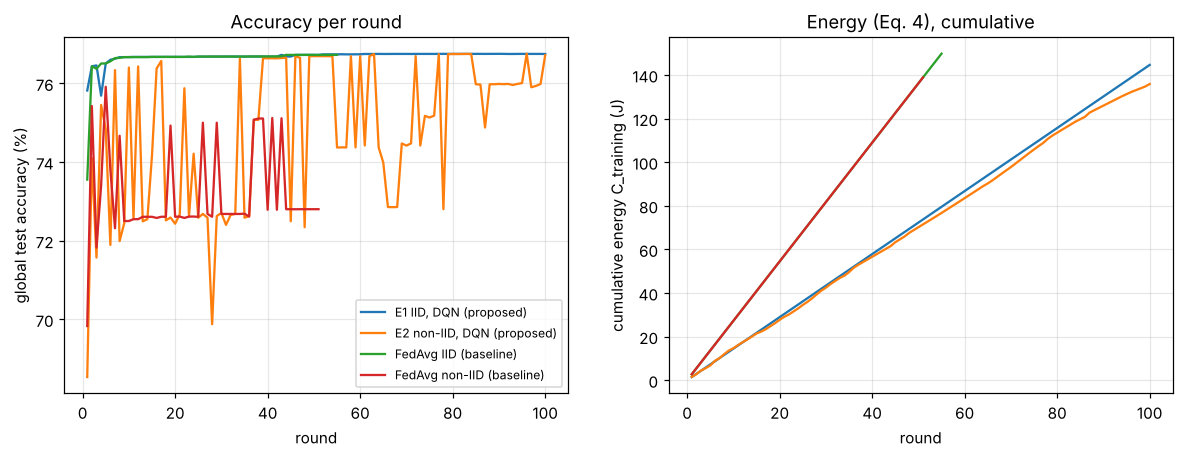

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, run in RUNS.items():
    L = [json.loads(l) for l in open(f"{R}/{run}/seed0/log.jsonl") if '"global_test_acc"' in l]
    ax[0].plot([x["round"] for x in L], [100*x["global_test_acc"] for x in L], label=name)
    ax[1].plot([x["round"] for x in L], [x["energy_cum"] for x in L], label=name)
ax[0].set(xlabel="round", ylabel="global test accuracy (%)", title="Accuracy per round")
ax[1].set(xlabel="round", ylabel="cumulative energy C_training (J)", title="Energy (Eq. 4), cumulative")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3); ax[1].grid(alpha=.3)
plt.show()

## Round-to-round variation
Non-IID accuracy swings by several points between rounds (it depends on which clients are selected). A single-round value can therefore land on a high or low point, so means over 10 rounds are reported too.

In [ ]:
rows = {}
for name, run in RUNS.items():
    a = np.array([json.loads(l)["global_test_acc"] for l in open(f"{R}/{run}/seed0/log.jsonl") if '"global_test_acc"' in l]) * 100
    r = {"round 50": a[49]}
    r.update({"rounds 41-50 mean": a[40:50].mean(), "rounds 41-50 min": a[40:50].min(), "rounds 41-50 max": a[40:50].max()})
    if len(a) >= 100:
        r.update({"round 100": a[99], "rounds 91-100 mean": a[90:100].mean(),
                  "rounds 91-100 min": a[90:100].min(), "rounds 91-100 max": a[90:100].max()})
    rows[name] = r
display(pd.DataFrame(rows).T.round(2))

,round 50,rounds 41-50 mean,rounds 41-50 min,rounds 41-50 max,round 100,rounds 91-100 mean,rounds 91-100 min,rounds 91-100 max
"E1 IID, DQN (proposed)",76.73,76.71,76.68,76.73,76.75,76.75,76.75,76.75
"E2 non-IID, DQN (proposed)",76.69,75.81,72.34,76.69,76.72,76.12,75.90,76.76
FedAvg IID (baseline),76.73,76.71,76.68,76.73,NaN,NaN,NaN,NaN
FedAvg non-IID (baseline),72.80,73.26,72.79,75.12,NaN,NaN,NaN,NaN


## Confusion matrix: E2 non-IID, DQN, round 50

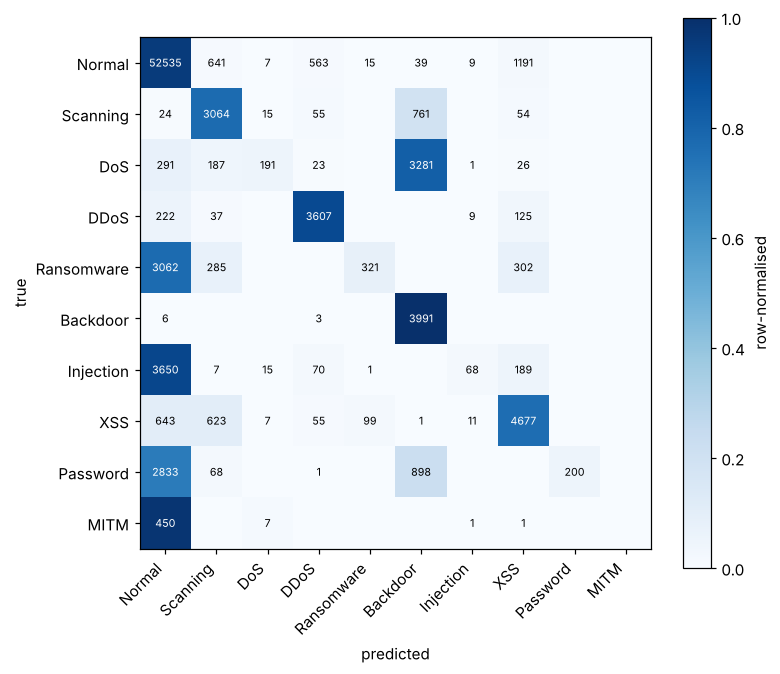

In [ ]:
cm = np.array(M("e2_noniid_dqn", 50)["global"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] / cm[i].sum() > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); fig.colorbar(im, label="row-normalised")
plt.show()

## ROC curve (micro-average, one-vs-rest): proposed model, round 50 (paper Fig. 7 style)

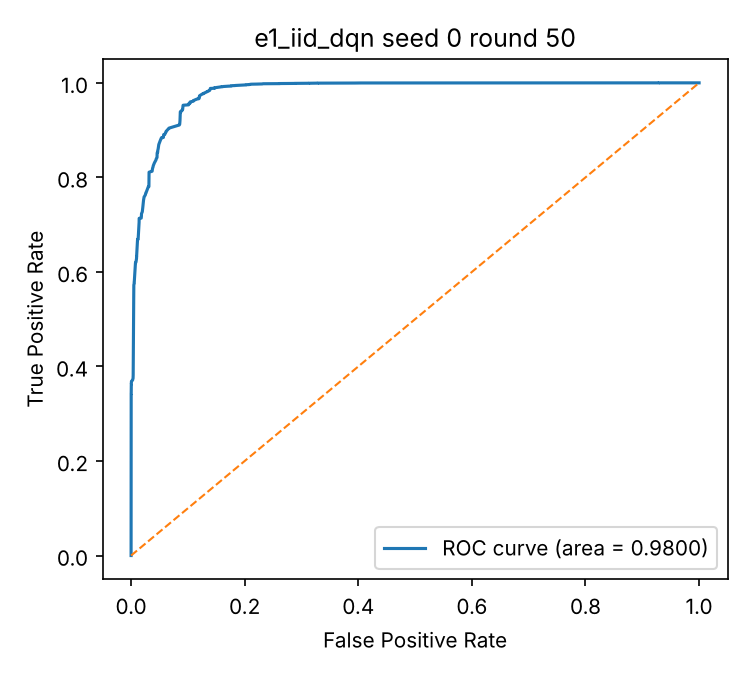

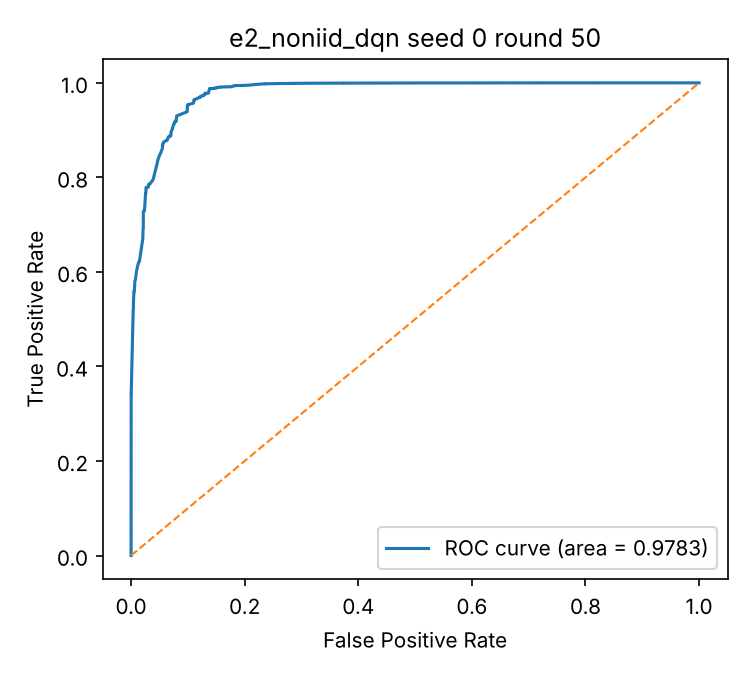

In [ ]:
display(Image(f"{R}/e1_iid_dqn/seed0/roc_round50.png"))
display(Image(f"{R}/e2_noniid_dqn/seed0/roc_round50.png"))

## Data: class counts vs Table II and client partitions (fixed seed 0)

 vs Table II [PAPER, p.8] and the split [GAP-FILL G1]

| class | in_file | paper_train | ours_train | paper_test | ours_test | unused | short_train | short_test |
|---|---|---|---|---|---|---|---|---|
| Normal | 300000 | 245000 | 245000 | 55000 | 55000 | 0 | 0 | 0 |
| Scanning | 20000 | 20000 | 16027 | 3973 | 3973 | 0 | 3973 | 0 |
| DoS | 20000 | 20000 | 16000 | 4000 | 4000 | 0 | 4000 | 0 |
| DDoS | 20000 | 20000 | 16000 | 4000 | 4000 | 0 | 4000 | 0 |
| Ransomware | 20000 | 16030 | 16030 | 3970 | 3970 | 0 | 0 | 0 |
| Backdoor | 20000 | 20000 | 16000 | 4000 | 4000 | 0 | 4000 | 0 |
| Injection Attack | 20000 | 20000 | 16000 | 4000 | 4000 | 0 | 4000 | 0 |
| XSS | 20000 | 13844 | 13844 | 6116 | 6116 | 40 | 0 | 0 |
| Password Violations | 20000 | 20000 | 16000 | 4000 | 4000 | 0 | 4000 | 0 |
| MITM | 1043 | 593 | 584 | 459 | 459 | 0 | 9 | 0 |

Totals: train 371,485 (paper 395,467), test 89,518 (paper 89,518).
`type` values not in Table II: none




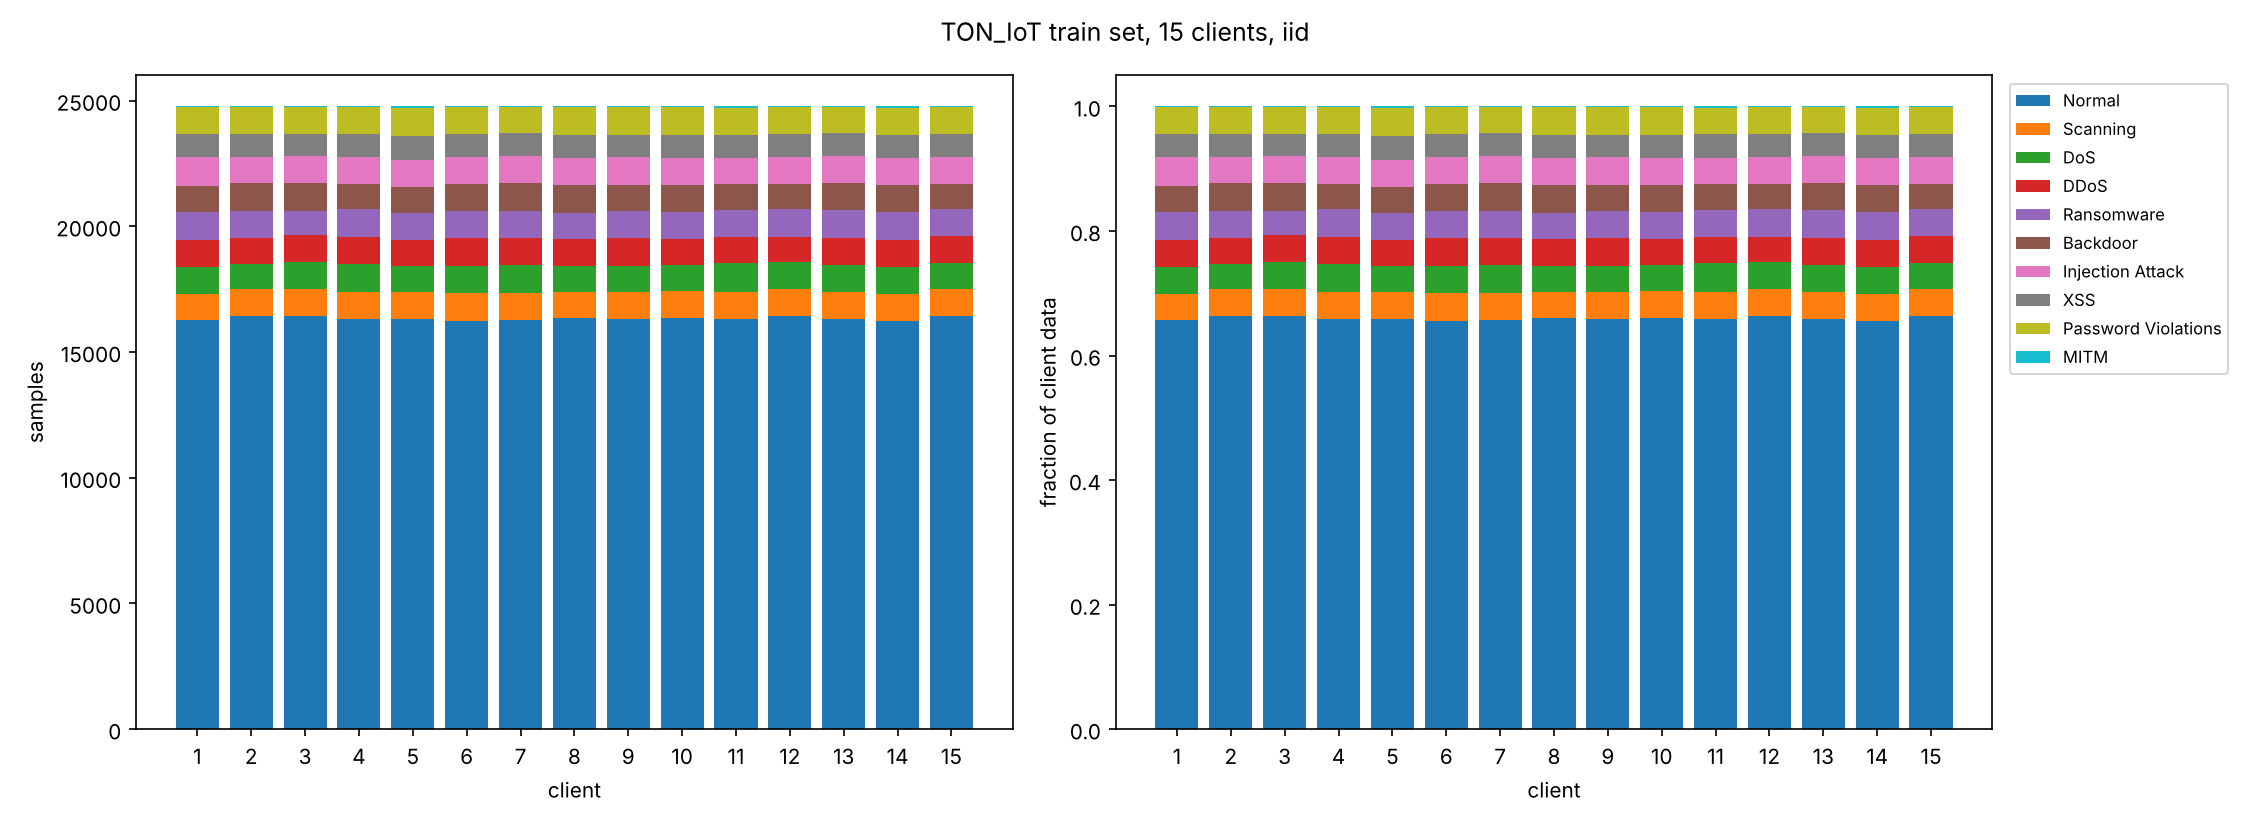

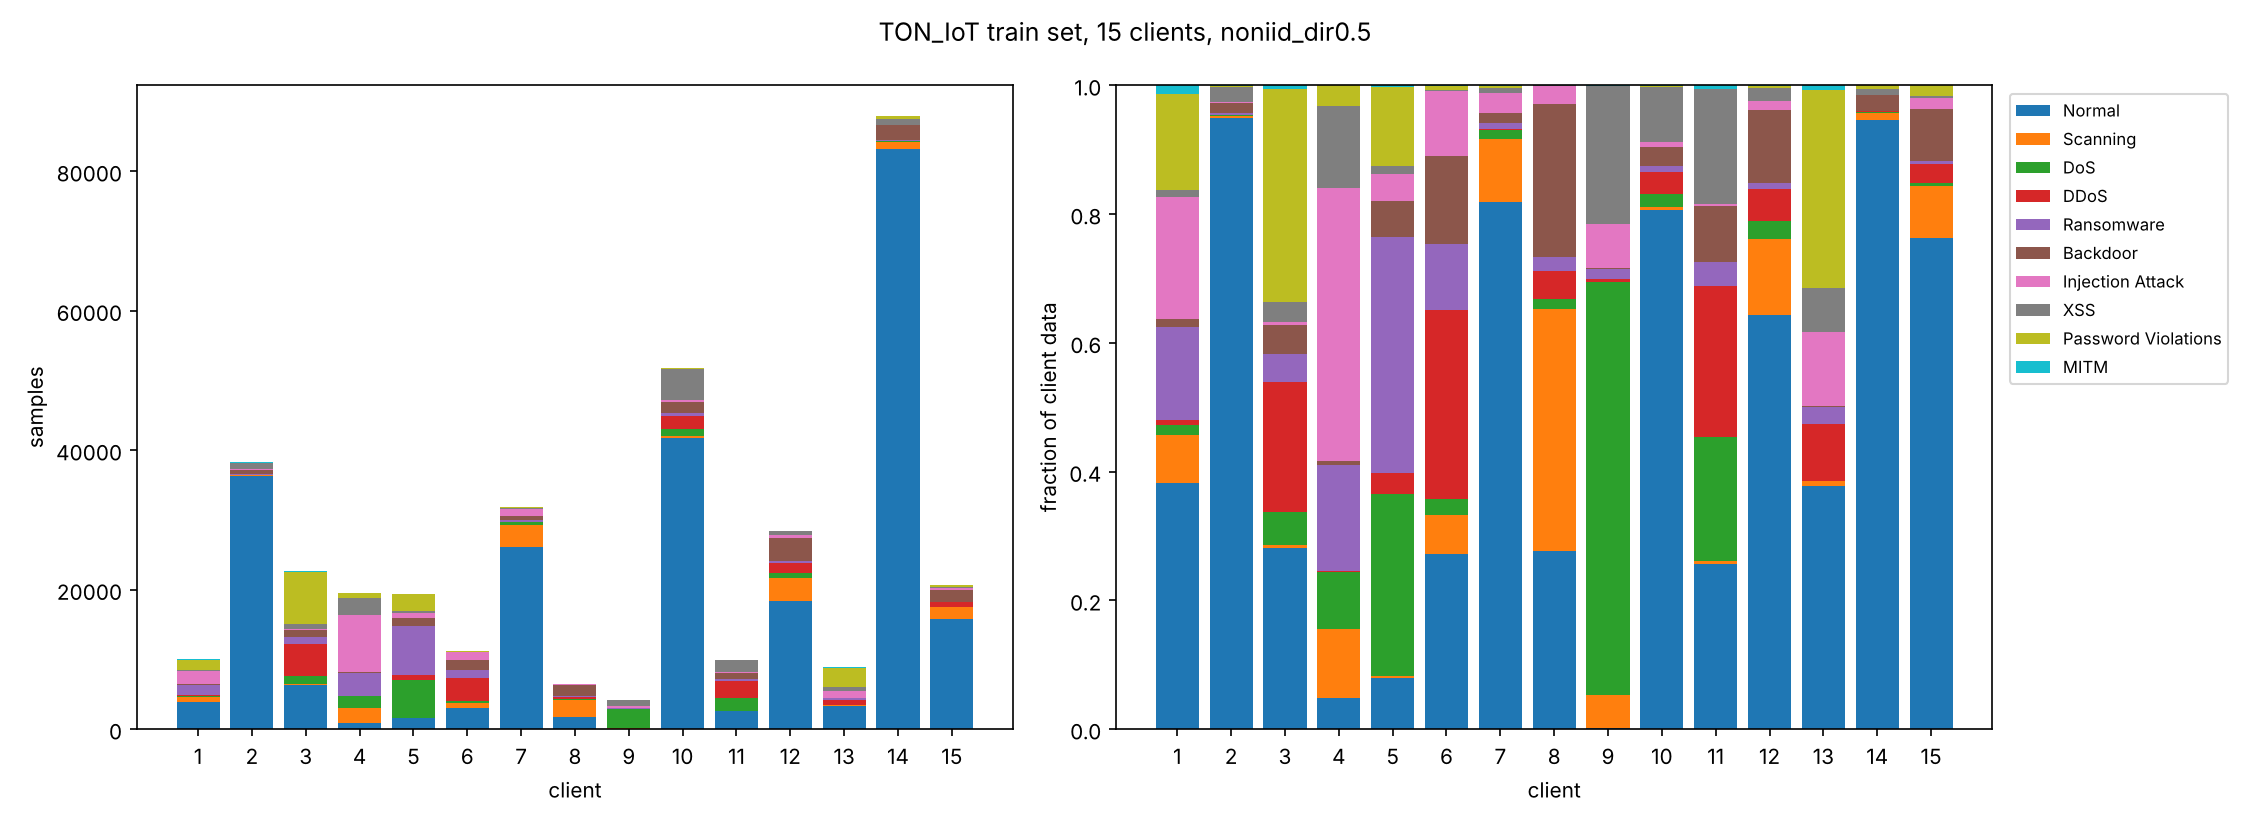

In [ ]:
print(open("kaur2024/results/phase1_data_report.md").read().split("## Client partition")[0].split("## Class counts")[1])
display(Image("kaur2024/results/partitions/class_distribution_iid.png"))
display(Image("kaur2024/results/partitions/class_distribution_noniid_dir0.5.png"))

## Why the accuracy is far below the paper's 99.95% (diagnostics)
- **Min-max scaling (Eq. 19) on heavy-tailed columns.** Byte, packet and duration values end up near
  0 for 99% of rows, so the model effectively sees only the one-hot flags
  (`kaur2024/results/extra/diag_duplicate_labels.txt`, SPEC §8).
- **The model underfits.** It is not limited by the data: for 3,661 of the 3,970 Ransomware test rows,
  the identical feature vector occurs in train with the same label.
- **The paper's Adam with η = 0.2 collapses to one class.** SGD with η = 0.2 is used instead
  (`kaur2024/results/extra/diag_lr_collapse.txt`, SPEC §7).
- **60% of test rows duplicate a training row's features** (X3). The "unseen rows" columns score only
  the 35,438 test rows that never occur in train.

In [ ]:
print(open("kaur2024/results/extra/diag_lr_collapse.txt").read())
print(open("kaur2024/results/extra/diag_duplicate_labels.txt").read())

d = 158; dropped (>50 unique in train): ['dns_query', 'http_uri']; unseen test rows: 35438
| optimiser | lr | epoch-1 train loss | test acc | largest predicted-class share |
|---|---|---|---|---|
| Adam | 0.2 | 2.2048 | 0.6144 | 1.000 |
| SGD | 0.2 | 0.8861 | 0.6943 | 0.589 |
| Adam | 0.001 | 0.7460 | 0.7398 | 0.597 |

| class | test rows | duplicated in train | of those: train majority = same class | train majority = Normal | lookup-ceiling recall |
|---|---|---|---|---|---|
| Normal | 55000 | 33957 | 33629 | 33629 | 0.611 |
| Scanning | 3973 | 3117 | 3113 | 0 | 0.784 |
| DoS | 4000 | 2883 | 2878 | 3 | 0.720 |
| DDoS | 4000 | 1796 | 1741 | 3 | 0.435 |
| Ransomware | 3970 | 3963 | 3661 | 218 | 0.922 |
| Backdoor | 4000 | 3710 | 3710 | 0 | 0.927 |
| Injection | 4000 | 57 | 22 | 2 | 0.005 |
| XSS | 6116 | 3484 | 3058 | 4 | 0.500 |
| Password | 4000 | 1109 | 1055 | 3 | 0.264 |
| MITM | 459 | 4 | 2 | 0 | 0.004 |

Lookup on duplicated rows alone (unseen rows counted wrong): accuracy 0.5906


## How to score another model on exactly the same test set
```python
from evaluate import evaluate
m = evaluate(y_true, y_pred, y_score)                       # full test set (89,518 rows)
mask = np.load("kaur2024/results/partitions/unseen_test_mask.npy")
m_unseen = evaluate(y_true, y_pred, y_score, mask=mask)     # 35,438 unseen rows
```
Use the split in `kaur2024/results/partitions/` (`split_train_idx.npy`, `split_test_idx.npy`, client
partitions) so that both models see identical data.